In [2]:
library(parallel)
library(GenomicFeatures)
set.seed(1234)
library(repr)
library(motifmatchr)
library(fastmatch)
library(qlcMatrix)

library(ensembldb)
library(EnsDb.Hsapiens.v86)
library(AnnotationFilter)

library(Signac)
library(Seurat)
library(JASPAR2024)
library(TFBSTools)
library(BSgenome.Hsapiens.UCSC.hg38)
library(patchwork)
library(ggplot2)
library(Matrix)
library(zoo)
library(tidyr)

source("../multiome_methods/function_calls.r")
source("../multiome_methods/peak_gene_relations.r")
source("../multiome_methods/binding_site_identification.r")
source("../multiome_methods/binding_site_identification_parallel.r")
source("../multiome_methods/TF_activity.r")
source("../multiome_methods/signac_utils.r")

library(dplyr)

library(ggplot2)
library(hexbin)
library(RColorBrewer)
library(cowplot)
library(gridExtra)
library(ggExtra)

library(pheatmap)
library(purrr)
library(data.table)
library(Rsamtools)
library(stringi)


Loading required package: Matrix


Attaching package: ‘Matrix’


The following object is masked from ‘package:S4Vectors’:

    expand


Loading required package: slam

Loading required package: sparsesvd


Attaching package: ‘qlcMatrix’


The following objects are masked from ‘package:Biobase’:

    rowMax, rowMin


Loading required package: AnnotationFilter


Attaching package: 'ensembldb'


The following object is masked from 'package:stats':

    filter



Attaching package: 'Signac'


The following object is masked from 'package:qlcMatrix':

    corSparse


Loading required package: SeuratObject

Loading required package: sp


Attaching package: 'sp'


The following object is masked from 'package:IRanges':

    %over%



Attaching package: 'SeuratObject'


The following object is masked from 'package:GenomicRanges':

    intersect


The following object is masked from 'package:GenomeInfoDb':

    intersect


The following object is masked from 'package:IRanges':

    intersect


Th

In [ ]:
object_w_net = readRDS("objects_AVN_fibroblast/final_object_w_net.rds")

In [3]:
Links(object_w_net[["peaks"]])

GRanges object with 130 ranges and 8 metadata columns:
        seqnames              ranges strand |      score        gene
           <Rle>           <IRanges>  <Rle> |  <numeric> <character>
    [1]     chr1 162554479-162631373      * |  0.0774144        DDR2
    [2]     chr1 183927089-184037729      * |  0.0547466    COLGALT2
    [3]     chr1 183959089-184037729      * |  0.0565144    COLGALT2
    [4]     chr1 184021883-184037729      * |  0.0587301    COLGALT2
    [5]     chr1 203202728-203351489      * |  0.0934006        FMOD
    ...      ...                 ...    ... .        ...         ...
  [126]    chr21   45981737-46060766      * |  0.0693516      COL6A1
  [127]    chr21   45981737-46065293      * |  0.0713216      COL6A1
  [128]    chr21   45981737-46092617      * |  0.0788913      COL6A1
  [129]    chr21   45981737-46098289      * |  0.0637026      COL6A1
  [130]    chr21   45981737-46110219      * | -0.0795677      COL6A1
                          peak    zscore      pv

In [11]:
library(dplyr)
library(tidyr)
library(ggplot2)
plot_gene_regulator_pass <- function(df, pass = "pass_any", top_n = NULL,
                                     zero_bar_height = 0.05, title = NULL) {

  pass_col <- dplyr::case_when(
    pass %in% c("any", "pass_any") ~ "pass_any",
    pass %in% c("global", "pass_global") ~ "pass_global",
    pass %in% c("cluster_specific", "pass_cluster_specific") ~ "pass_cluster_specific",
    TRUE ~ pass
  )

  stopifnot(pass_col %in% colnames(df))

  plot_df <- df %>%
    filter(regulatorType %in% c("proximal","distal")) %>%
    mutate(
      regulatorType = factor(regulatorType, levels = c("proximal","distal")),
      passed = coalesce(.data[[pass_col]], FALSE)
    ) %>%
    group_by(gene, regulatorType) %>%
    summarise(
      total_n = n(),
      passed_n = sum(passed, na.rm = TRUE),
      .groups = "drop"
    )

  if (!is.null(top_n)) {
    top_genes <- plot_df %>%
      group_by(gene) %>%
      summarise(total = sum(total_n), .groups = "drop") %>%
      slice_max(total, n = top_n) %>%
      pull(gene)

    plot_df <- plot_df %>%
      filter(gene %in% top_genes)
  }

  plot_df <- plot_df %>%
    complete(
      gene,
      regulatorType = factor(c("proximal","distal"), levels = c("proximal","distal")),
      fill = list(total_n = 0, passed_n = 0)
    ) %>%
    mutate(
      total_n_plot = if_else(total_n == 0, zero_bar_height, as.numeric(total_n)),
      passed_n_plot = as.numeric(passed_n)
    )

  ggplot(plot_df, aes(x = gene, fill = regulatorType)) +
    geom_col(
      aes(y = total_n_plot),
      position = position_dodge(width = 0.8),
      width = 0.7,
      alpha = 0.35
    ) +
    geom_col(
      aes(y = passed_n_plot),
      position = position_dodge(width = 0.8),
      width = 0.7,
      alpha = 0.95
    ) +
    labs(
      x = "Gene",
      y = "Number of linked peaks",
      fill = "Regulator type",
      title = if (!is.null(title)) {
        title
      } else {
        paste0("Rows per gene and regulator type: ", pass_col)
      },
      subtitle = "Light bar = total peaks; dark overlay = passed peaks"
    ) +
    theme_classic() +
    theme(
      axis.text.x = element_text(angle = 90, hjust = 1)
    )
}

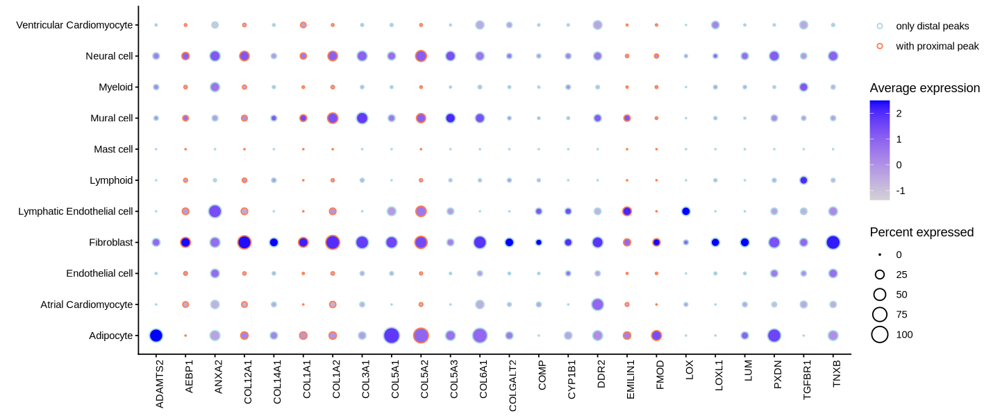

In [68]:
library(Seurat)
library(ggplot2)
options(repr.plot.width=12, repr.plot.height=5)
features <- c(
   "ADAMTS2", "AEBP1", "ANXA2", 
   "COL12A1", "COL14A1",  "COL1A1","COL1A2", "COL3A1", "COL5A1","COL5A2","COL5A3", "COL6A1", 
"COLGALT2", "COMP", "CYP1B1", "DDR2", "EMILIN1","FMOD", "LOX",  "LOXL1", "LUM", "PXDN", "TGFBR1","TNXB"
)

coral_features <- c(
  "FMOD", "EMILIN1", "COL5A2", "COL1A2", "COL1A1", "COL12A1", "AEBP1"
)

p <- DotPlot(
  object_w_net,
  features = features,
  assay = "RNA",
  group.by = "cell_type"
)

df <- p$data

df$feature_group <- ifelse(
  df$features.plot %in% coral_features,
  "with proximal peak",
  "only distal peaks"
)

df$features.plot <- factor(df$features.plot, levels = features)

p <- ggplot(df, aes(x = features.plot, y = id)) +
  geom_point(
    aes(
      size = pct.exp,
      fill = avg.exp.scaled,
      color = feature_group
    ),
    shape = 21,
    stroke = 0.8
  ) +
  scale_fill_gradientn(
    colors = c("lightgrey", "blue"),
    name = "Average expression"
  ) +
  scale_color_manual(
    values = c(
      "with proximal peak" = "coral",
      "only distal peaks" = "lightblue"
    ),
    name = NULL
  ) +
  scale_size(range = c(0, 6), name = "Percent expressed") +
  theme_classic() +
  theme(axis.text.x = element_text(angle = 90, hjust = 1)) +
  labs(x = NULL, y = NULL)

ggsave("dotplot_features.pdf", plot = p, width = 12, height = 5, dpi = 300)
p

In [12]:
options(repr.plot.width=8, repr.plot.height=4)
p<-plot_gene_regulator_pass(object_w_net@misc$peak_stats)
# save plot as pdf high resolution
ggsave("gene_regulator_pass_plot.pdf", plot = p, width = 8, height = 4, dpi = 300)

In [13]:
p<-plot_gene_regulator_pass(object_w_net@misc$peak_stats, pass = "pass_global")
ggsave("gene_regulator_pass_plot_global.pdf", plot = p, width = 8, height = 4, dpi = 300)

In [14]:
p<-plot_gene_regulator_pass(object_w_net@misc$peak_stats, pass = "pass_cluster_specific")
ggsave("gene_regulator_pass_plot_cluster_specific.pdf", plot = p, width = 8, height = 4, dpi = 300)

In [7]:
library(dplyr)
df <- object_w_net@misc$filtered.motif_enrichment[object_w_net@misc$filtered.motif_enrichment$proximal.motif_count > 0 ,]
motifs_per_gene_proximal <- df %>%
  group_by(gene) %>%
  summarise(
    n_motifs = n_distinct(motif),
    .groups = "drop"
  )

In [8]:
library(dplyr)
df <- object_w_net@misc$filtered.motif_enrichment[object_w_net@misc$filtered.motif_enrichment$proximal.motif_count > 0 ,]
motifs_per_gene_proximal <- df %>%
  group_by(gene) %>%
  summarise(
    n_motifs = n_distinct(motif),
    .groups = "drop"
  )

In [9]:

df <- object_w_net@misc$motif_enrichment[object_w_net@misc$motif_enrichment$distal.motif_count > 0 & object_w_net@misc$motif_enrichment$proximal.motif_count == 0,]
motifs_per_gene_only_distal <- df %>%
  group_by(gene) %>%
  summarise(
    n_motifs = n_distinct(motif),
    .groups = "drop"
  )

In [10]:

df <- object_w_net@misc$filtered.motif_enrichment[object_w_net@misc$filtered.motif_enrichment$distal.motif_count > 0 & object_w_net@misc$filtered.motif_enrichment$proximal.motif_count == 0,]
motifs_per_gene_only_distal_enriched <- df %>%
  group_by(gene) %>%
  summarise(
    n_motifs = n_distinct(motif),
    .groups = "drop"
  )

In [ ]:
join on columns gene: motifs_per_gene_only_distal, motifs_per_gene_only_distal_enriched, motifs_per_gene_proximal
rename the columns with suffixes _only_distal, _only_distal_enriched, _proximal respectively

the make a plot like plot_gene_regulator_pass, but all proximal always pass and the distal pass if they are in the enriched set (motifs_per_gene_only_distal_enriched)



[1] 720

In [ ]:

motif_summary_joined <- motifs_per_gene_only_distal %>%
  rename(n_motifs_only_distal = n_motifs) %>%
  full_join(
    motifs_per_gene_only_distal_enriched %>%
      rename(n_motifs_only_distal_enriched = n_motifs),
    by = "gene"
  ) %>%
  full_join(
    motifs_per_gene_proximal %>%
      rename(n_motifs_proximal = n_motifs),
    by = "gene"
  ) %>%
  mutate(
    across(starts_with("n_motifs"), ~replace_na(.x, 0))
  )

In [12]:
motif_summary_joined

gene,n_motifs_only_distal,n_motifs_only_distal_enriched,n_motifs_proximal
<chr>,<int>,<int>,<int>
ADAMTS2,217,198,0
AEBP1,71,70,54
ANXA2,47,43,0
COL12A1,7,7,66
COL14A1,192,164,0
COL1A1,230,156,21
COL1A2,258,113,132
COL3A1,282,138,0
COL5A1,516,226,0


In [13]:
colSums(motif_summary_joined[, -1])

n_motifs_only_distal n_motifs_only_distal_enriched 
                         4600                          2792 
            n_motifs_proximal 
                          498

In [16]:
plot_motif_distal_proximal_pass <- function(motif_summary_joined,
                                            top_n = NULL,
                                            zero_bar_height = 0.05) {
  library(dplyr)
  library(tidyr)
  library(ggplot2)

  plot_df <- motif_summary_joined %>%
    transmute(
      gene,

      distal_total = n_motifs_only_distal,
      distal_passed = n_motifs_only_distal_enriched,

      proximal_total = n_motifs_proximal,
      proximal_passed = n_motifs_proximal
    ) %>%
    pivot_longer(
      cols = -gene,
      names_to = c("regulatorType", ".value"),
      names_pattern = "(distal|proximal)_(total|passed)"
    ) %>%
    mutate(
      regulatorType = factor(regulatorType, levels = c("proximal","distal")),
      total_plot = if_else(total == 0, zero_bar_height, as.numeric(total)),
      passed_plot = as.numeric(passed)
    )

  if (!is.null(top_n)) {
    top_genes <- plot_df %>%
      group_by(gene) %>%
      summarise(total_all = sum(total), .groups = "drop") %>%
      slice_max(total_all, n = top_n) %>%
      pull(gene)

    plot_df <- plot_df %>%
      filter(gene %in% top_genes)
  }

  ggplot(plot_df, aes(x = gene, fill = regulatorType)) +
    geom_col(
      aes(y = total_plot),
      position = position_dodge(width = 0.8),
      width = 0.7,
      alpha = 0.35
    ) +
    geom_col(
      aes(y = passed_plot),
      position = position_dodge(width = 0.8),
      width = 0.7,
      alpha = 0.95
    ) +
    labs(
      x = "Gene",
      y = "Number of motifs",
      fill = "Regulator type",
      title = "Motifs found in peaks per gene: only in distal vs proximal",
      subtitle = "Light bar = total motifs; dark overlay = passed motifs. Proximal always passes; distal passes if enriched."
    ) +
    theme_classic() +
    theme(
      axis.text.x = element_text(angle = 90, hjust = 1)
    )
}

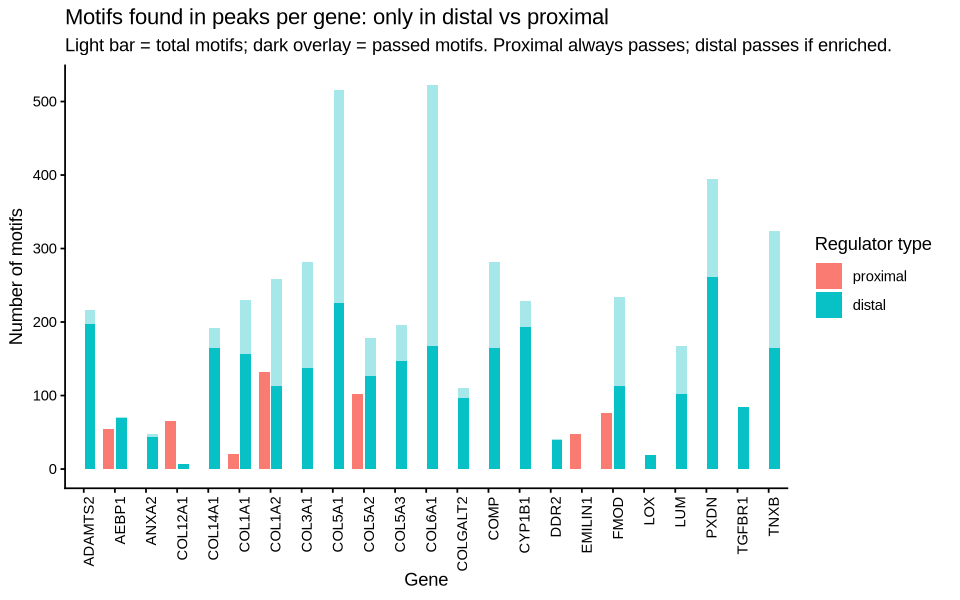

In [64]:
p<-plot_motif_distal_proximal_pass(motif_summary_joined)
ggsave("motif_distal_proximal_pass_plot.pdf", plot = p, width = 10, height = 5, dpi = 300)
p

In [67]:
str(object_w_net@misc, max.level=1)

List of 12
 $ markers.annotated        :'data.frame':	4075 obs. of  8 variables:
 $ peak_stats               :'data.frame':	130 obs. of  51 variables:
 $ peak_stats.filtered      :'data.frame':	122 obs. of  51 variables:
 $ motifs.inProximalPeaks   :List of 23
 $ motifs.inDistalPeaks     :List of 23
 $ motif_enrichment         :'data.frame':	16560 obs. of  16 variables:
 $ filtered.motif_enrichment:'data.frame':	3290 obs. of  16 variables:
 $ motif_stats              :'data.frame':	3290 obs. of  26 variables:
 $ motif2TF                 :List of 720
 $ TF2motif                 :List of 668
 $ seedNetwork              :List of 5
 $ context_subNetwork       :List of 5


In [74]:
str(object_w_net@misc$context_subNetwork, max.level=1)

List of 5
 $ colagen_fibral_orga                     :'data.frame':	935 obs. of  6 variables:
 $ colagen_fibral_orga_omni_path           :'data.frame':	927 obs. of  6 variables:
 $ colagen_fibral_orga_omni_path_cl_unsp   :'data.frame':	927 obs. of  6 variables:
 $ colagen_fibral_orga_omni_path_full_prior:'data.frame':	1138 obs. of  6 variables:
 $ colagen_fibral_orga_complete            :'data.frame':	2093 obs. of  6 variables:


In [86]:
unique(df["color"])

,color
,<chr>
ADAMTS7.1,black
AEBP1.1,red
AEBP1.2,green
AEBP1.13,yellow
ANXA2.1,gray
COL1A1.1,blue


In [78]:
df[df[["to"]] =="TLL1",]

,from,to,color,priorTF,reg_type,in.prom
,<chr>,<chr>,<chr>,<lgl>,<int>,<int>
TLL1,NKX2-5,TLL1,black,TRUE,2,1


In [90]:
# motif not in peaks 
head(df[df[["color"]] =="black",])

,from,to,color,priorTF,reg_type,in.prom
,<chr>,<chr>,<chr>,<lgl>,<int>,<int>
ADAMTS7.1,HR,ADAMTS7,black,TRUE,2,1
ADAMTS7.2,HTATIP2,ADAMTS7,black,TRUE,2,1
ADAMTS7.3,SSRP1,ADAMTS7,black,TRUE,2,1
ADAMTS7.4,TFAP2A,ADAMTS7,black,TRUE,2,1
ADAMTS7.5,ZBTB16,ADAMTS7,black,TRUE,2,1
ATP7A.1,ESR1,ATP7A,black,TRUE,2,1


In [88]:
# unknown TF/ not in data base
head(df[df[["color"]] =="gray",])

,from,to,color,priorTF,reg_type,in.prom
,<chr>,<chr>,<chr>,<lgl>,<int>,<int>
ANXA2.1,CAMTA1,ANXA2,gray,TRUE,2,1
ANXA2.2,STAT6,ANXA2,gray,TRUE,2,1
COL1A1.3,CIITA,COL1A1,gray,TRUE,2,1
COL1A1.5,DLX5,COL1A1,gray,TRUE,2,1
COL1A1.9,LEF1,COL1A1,gray,TRUE,2,1
COL1A1.11,MRTFA,COL1A1,gray,TRUE,2,1


In [ ]:
# gene w/o link,
head(df[df[["color"]] =="blue",])

gene,cluster,motif,proximal.motif_count,proximal.background_count,log2FC.proximal,t_stat.proximal,p_value.proximal,p_adjust.proximal,distal.motif_count,distal.background_count,log2FC.distal,t_stat.distal,p_value.distal,p_adjust.distal,promoter.motif_count
<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>


In [100]:
colSums(motifs_per_gene[,-1])

n_motifs_enriched 
             1519

In [ ]:
str(object_w_net@misc$context_subNetwork,max.level=)

List of 5
 $ colagen_fibral_orga                     :'data.frame':	935 obs. of  6 variables:
  ..$ from    : chr [1:935] "ZBTB33" "PURA" "ATF1" "CTCFL" ...
  ..$ to      : chr [1:935] "TLL1" "PLOD1" "LOXL3" "LUM" ...
  ..$ color   : chr [1:935] "black" "black" "black" "blue" ...
  ..$ priorTF : logi [1:935] TRUE TRUE TRUE TRUE FALSE FALSE ...
  ..$ reg_type: int [1:935] 2 2 2 2 2 2 2 2 2 2 ...
  ..$ in.prom : int [1:935] 1 1 1 1 3 1 3 1 1 3 ...
 $ colagen_fibral_orga_omni_path           :'data.frame':	927 obs. of  6 variables:
  ..$ from    : chr [1:927] "NFYA" "PPARG" "FOXG1" "TBX20" ...
  ..$ to      : chr [1:927] "LUM" "LUM" "LUM" "LUM" ...
  ..$ color   : chr [1:927] "blue" "blue" "red" "yellow" ...
  ..$ priorTF : logi [1:927] TRUE TRUE FALSE FALSE FALSE FALSE ...
  ..$ reg_type: int [1:927] 2 2 2 2 2 2 2 2 2 2 ...
  ..$ in.prom : int [1:927] 3 1 3 1 3 1 1 3 1 1 ...
 $ colagen_fibral_orga_omni_path_cl_unsp   :'data.frame':	927 obs. of  6 variables:
  ..$ from    : chr [1:927] "NF

In [6]:
full_priorGRN <- read.csv("/nfs/home/students/m.back/swarm/backend/calc_multiome_scores/multiome_tf_regulation/notebooks_pipeline/objects_AVN_fibroblast/gene_tf_relations_AVN_fibroblasts.csv")


In [24]:
library(dplyr)
library(tidyr)

full_priorGRN_split <- full_priorGRN %>%
  separate_rows(TF, sep = "_")

found and passed 46 Transcription factors that bind in regulatory regions for seed DDR2 Fibroblast



[1] "ATF4"
[1] "CEBPB"
[1] "CEBPG"
[1] "MAX"
[1] "MYC"
[1] "ZNF24"
[1] "ZNF75A"
[1] "PITX2"
[1] "ZNF75D"
[1] "ATF2"
[1] "ATF7"
[1] "MAFK"
[1] "BACH2.1"
[1] "JUN"
[1] "CEBPA"
[1] "CREB1"
[1] "CREM"
[1] "DPRX"
[1] "ERF"
[1] "FOXO1"
[1] "HOXB13"
[1] "FOS"
[1] "JUN.1"
[1] "JUND"
[1] "FOSL2"
[1] "JUND.1"
[1] "FOXD3"
[1] "PITX1"
[1] "GSC"
[1] "GSC2"
[1] "KLF4"
[1] "MEIS3"
[1] "NR2C2.1"
[1] "OTX1"
[1] "OTX2"
[1] "PITX3"
[1] "PRDM1"
[1] "PRDM9"
[1] "RBPJ"
[1] "SMAD2"
[1] "STAT3"
[1] "TCF7L2"
[1] "ZNF740"
[1] "ZNF85"
[1] "ZSCAN29"
[1] "ZSCAN31"


found and passed 88 Transcription factors that bind in regulatory regions for seed COLGALT2 Fibroblast



[1] "RORA"
[1] "JDP2"
[1] "TBX20"
[1] "RARA.1"
[1] "TBX4"
[1] "TBX5"
[1] "TEAD3"
[1] "ZNF184"
[1] "PITX2"
[1] "BACH1"
[1] "TBX21"
[1] "BACH2"
[1] "BATF"
[1] "JUN"
[1] "BATF3"
[1] "BNC2"
[1] "CEBPA"
[1] "CEBPD"
[1] "EBF1"
[1] "EBF3"
[1] "EOMES"
[1] "ESRRA"
[1] "ESRRB"
[1] "ETV2"
[1] "FOXI1"
[1] "ETV5"
[1] "FOXO1"
[1] "FLI1"
[1] "FOS"
[1] "JUNB"
[1] "JUNB.1"
[1] "JUND"
[1] "JUND.1"
[1] "FOSB"
[1] "FOSL1"
[1] "JUN.1"
[1] "FOSL2"
[1] "FOXD3"
[1] "PITX1"
[1] "ELF1"
[1] "GATA2"
[1] "GATA4"
[1] "GATA6"
[1] "GSC"
[1] "GSC2"
[1] "HLF"
[1] "TBX3"
[1] "HOXC11"
[1] "IRF3"
[1] "IRF7"
[1] "MAF"
[1] "NFE2"
[1] "MAFG"
[1] "NFE2L1"
[1] "MEIS1"
[1] "MEIS3"
[1] "NFIC"
[1] "NFIL3"
[1] "NFYB"
[1] "NKX2-3"
[1] "NKX2-4"
[1] "NKX2-5"
[1] "NKX2-8"
[1] "NR2F2"
[1] "NR6A1"
[1] "OTX1"
[1] "OTX2"
[1] "PBX1"
[1] "PITX3"
[1] "PRDM1"
[1] "SMAD2"
[1] "SOX12"
[1] "SP5"
[1] "SPIC"
[1] "TBR1"
[1] "TBX18"
[1] "TBX2"
[1] "TEAD1"
[1] "TEAD2"
[1] "TEAD4"
[1] "TRPS1"
[1] "ZIM3"
[1] "ZNF263"
[1] "ZNF274"
[1] "ZNF410"
[1] "ZNF6

found and passed 195 Transcription factors that bind in regulatory regions for seed FMOD Fibroblast



[1] "SP7"
[1] "RXRA"
[1] "VDR"
[1] "ZNF354C"
[1] "EWSR1-FLI1"
[1] "RARA"
[1] "SREBF1"
[1] "SREBF2"
[1] "HSF1"
[1] "MSC"
[1] "MYF6"
[1] "NEUROG2"
[1] "TFAP4"
[1] "RARA.1"
[1] "EGR2"
[1] "HSF2"
[1] "HSF4"
[1] "TBX4"
[1] "TBX5"
[1] "TEAD3"
[1] "HEY1"
[1] "TP53"
[1] "MTF1"
[1] "E2F1"
[1] "ZNF24"
[1] "HES6"
[1] "RXRB.1"
[1] "RXRG.1"
[1] "ZBTB32"
[1] "ZNF135"
[1] "ZNF460"
[1] "ZNF766"
[1] "POU2F1"
[1] "SOX2"
[1] "ZFP14"
[1] "ZNF669"
[1] "ZNF184"
[1] "ZNF213"
[1] "SP1"
[1] "SP2"
[1] "SP4"
[1] "KLF14"
[1] "HES5"
[1] "PITX2"
[1] "ZNF75D"
[1] "IKZF2"
[1] "PGR"
[1] "ZNF547"
[1] "FEZF2"
[1] "ARNT"
[1] "HIF1A"
[1] "BARX1"
[1] "BSX"
[1] "CDX2"
[1] "CEBPA"
[1] "CEBPD"
[1] "CEBPG.1"
[1] "CREB3L4.1"
[1] "HOXB13"
[1] "DLX1"
[1] "DLX6"
[1] "E2F2"
[1] "E2F4"
[1] "EBF3"
[1] "EGR1"
[1] "EGR3"
[1] "EGR4"
[1] "ETV7"
[1] "SPDEF"
[1] "EN1"
[1] "EN2"
[1] "ERF"
[1] "FOXO1"
[1] "ETV5"
[1] "FOXI1"
[1] "FOSL2"


... (274 outputs left out)

colors are numbers at the end: is this going wrong here already?



  [1] red    blue   red    red    red    red    red    red    red    green 
 [11] yellow red    red    yellow yellow red    red    yellow red    red   
 [21] red    green  yellow green  red    red    red    yellow red    green 
 [31] red    red    green  red    green  red    red    green  red    red   
 [41] red    red    red    red    red    red    red    red    red    green 
 [51] red    red    yellow red    red    red    red    yellow red    yellow
 [61] red    yellow yellow yellow yellow yellow yellow red    red    red   
 [71] yellow red    red    red    red    red    red    red    red    red   
 [81] red    red    red    red    red    red    red    red    red    yellow
 [91] red    green  green  red    yellow red    yellow red    yellow green 
[101] yellow yellow red    yellow red    red    green  red    red    red   
[111] red    yellow red    green  yellow yellow yellow yellow red    red   
[121] red    red    red    red    red    red    yellow red    red    red   
[131] yellow

edge_color at the end of get_subnetwork



  [1] red    blue   red    red    red    red    red    red    red    green 
 [11] yellow red    red    yellow yellow red    red    yellow red    red   
 [21] red    green  yellow green  red    red    red    yellow red    green 
 [31] red    red    green  red    green  red    red    green  red    red   
 [41] red    red    red    red    red    red    red    red    red    green 
 [51] red    red    yellow red    red    red    red    yellow red    yellow
 [61] red    yellow yellow yellow yellow yellow yellow red    red    red   
 [71] yellow red    red    red    red    red    red    red    red    red   
 [81] red    red    red    red    red    red    red    red    red    yellow
 [91] red    green  green  red    yellow red    yellow red    yellow green 
[101] yellow yellow red    yellow red    red    green  red    red    red   
[111] red    yellow red    green  yellow yellow yellow yellow red    red   
[121] red    red    red    red    red    red    yellow red    red    red   
[131] yellow

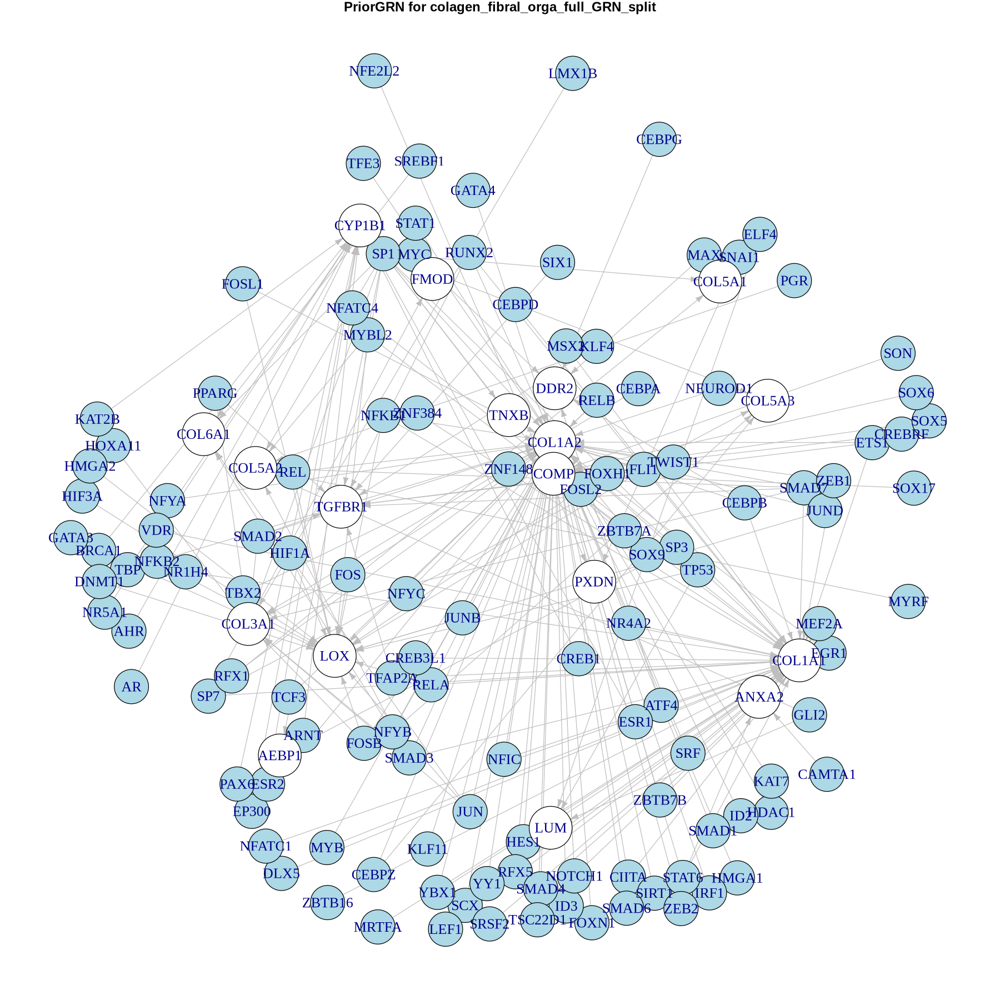

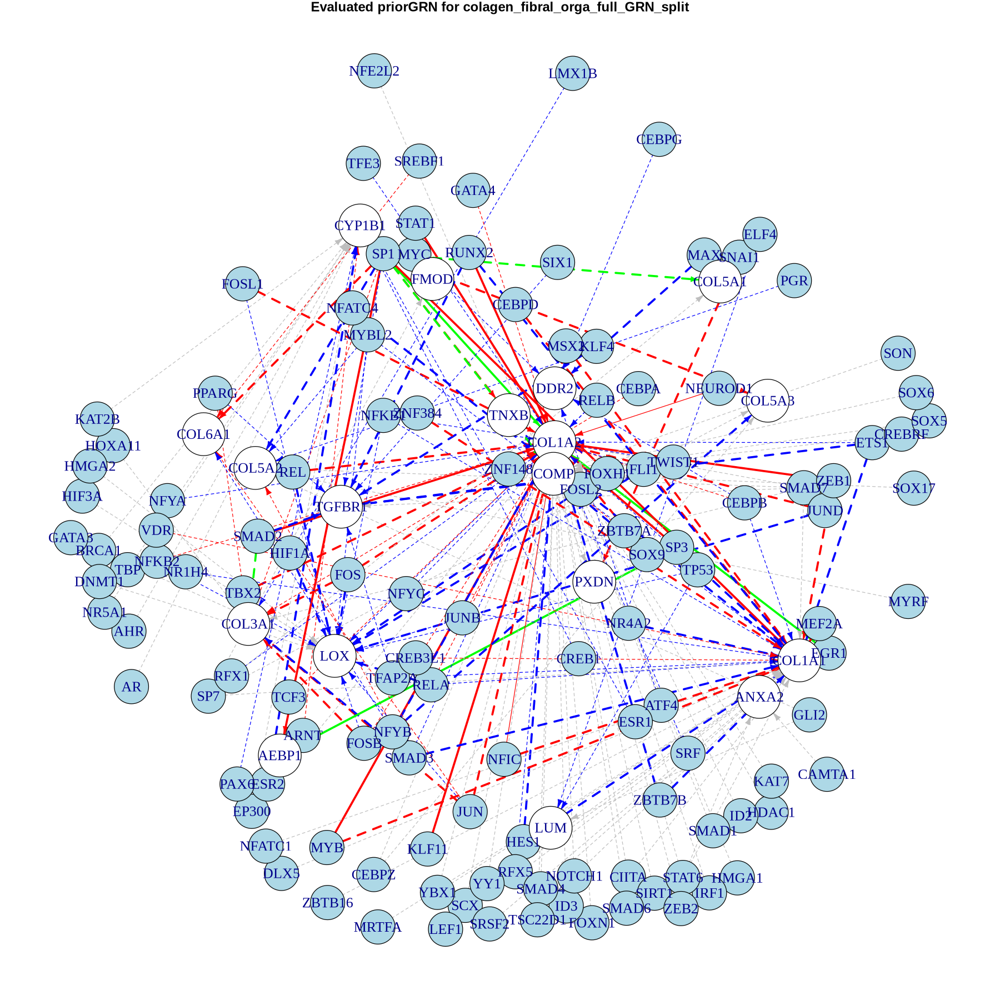

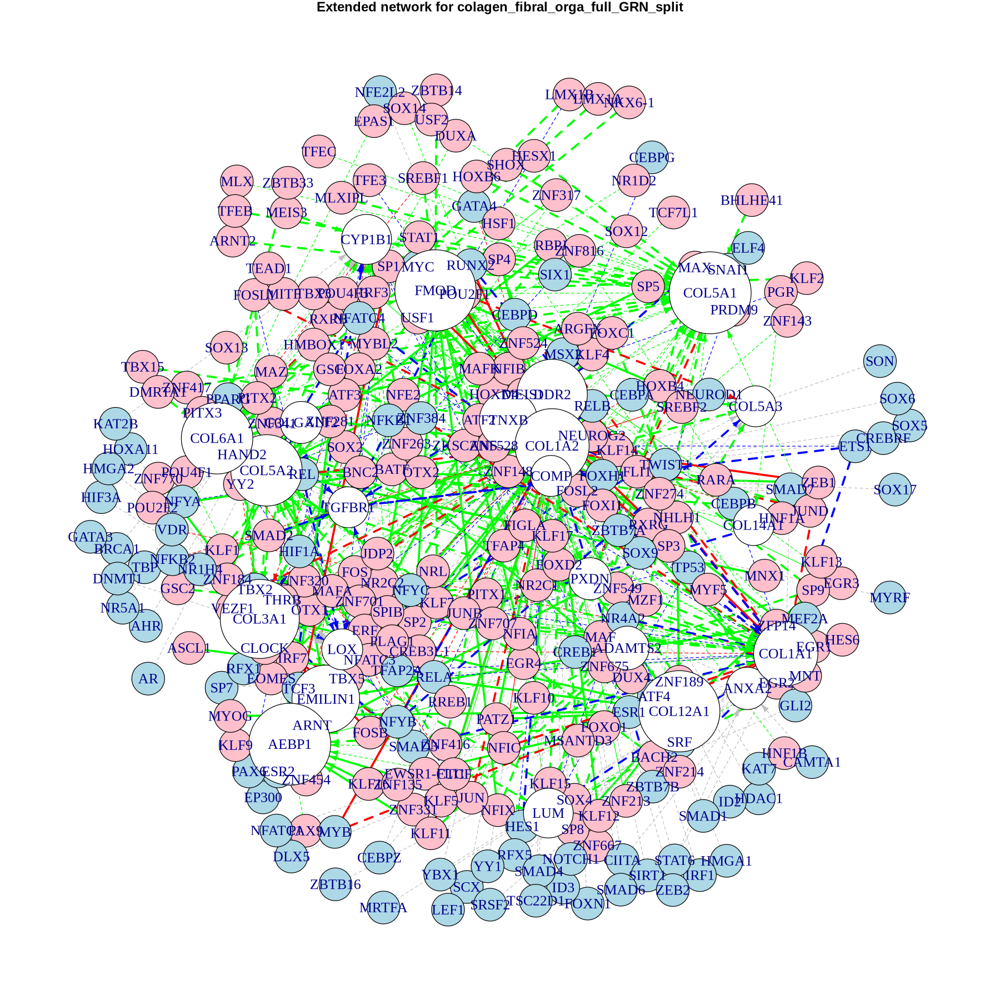

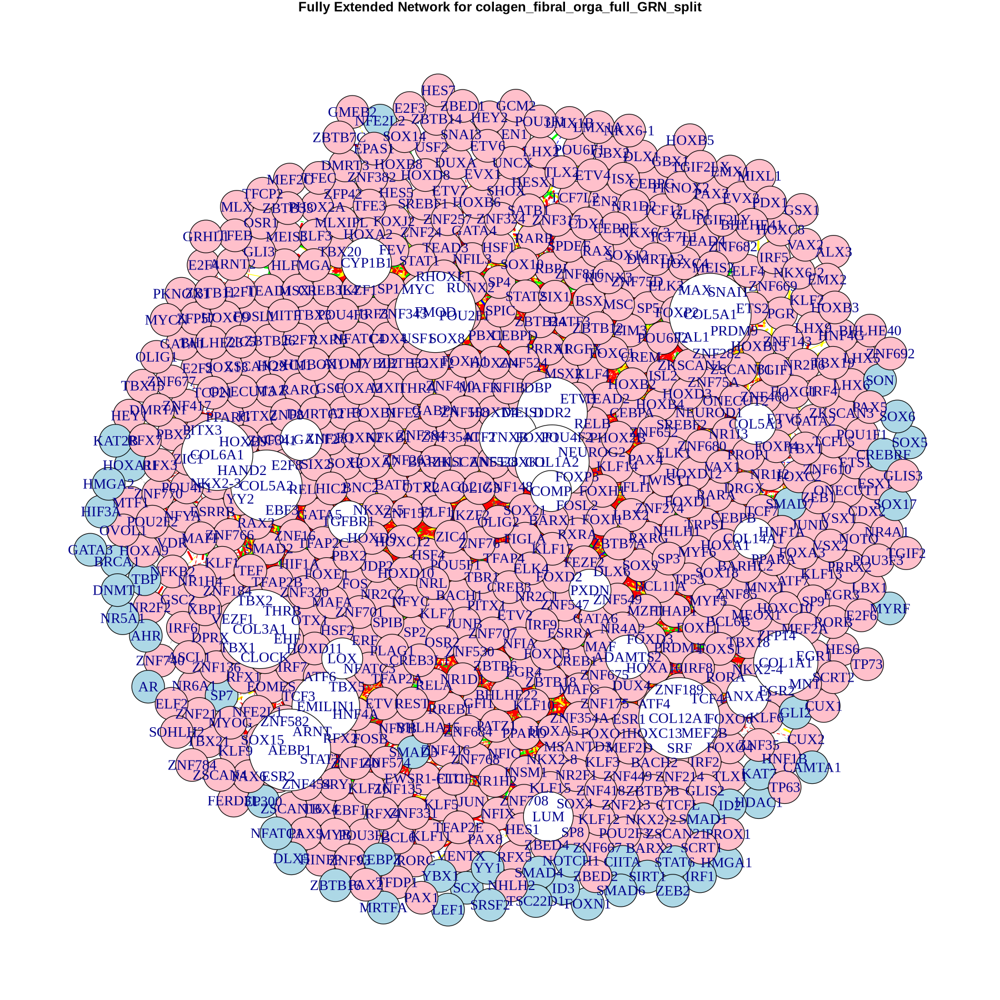

In [25]:
object_w_net<-draw_subNetwork_for_context(object=object_w_net, 
        gene_list= object_w_net@misc$peak_stats$gene %>% unique(),
        cluster.specific=TRUE,
        priorGRN=full_priorGRN_split,
        cluster="Fibroblast",
        context_name='colagen_fibral_orga_full_GRN_split',resolution=20,pointsize=50, sd=5, score=-0.5
        )

found and passed 46 Transcription factors that bind in regulatory regions for seed DDR2 Fibroblast



[1] "ATF4"
[1] "CEBPB"
[1] "CEBPG"
[1] "MAX"
[1] "MYC"
[1] "ZNF24"
[1] "ZNF75A"
[1] "PITX2"
[1] "ZNF75D"
[1] "ATF2"
[1] "ATF7"
[1] "MAFK"
[1] "BACH2.1"
[1] "JUN"
[1] "CEBPA"
[1] "CREB1"
[1] "CREM"
[1] "DPRX"
[1] "ERF"
[1] "FOXO1"
[1] "HOXB13"
[1] "FOS"
[1] "JUN.1"
[1] "JUND"
[1] "FOSL2"
[1] "JUND.1"
[1] "FOXD3"
[1] "PITX1"
[1] "GSC"
[1] "GSC2"
[1] "KLF4"
[1] "MEIS3"
[1] "NR2C2.1"
[1] "OTX1"
[1] "OTX2"
[1] "PITX3"
[1] "PRDM1"
[1] "PRDM9"
[1] "RBPJ"
[1] "SMAD2"
[1] "STAT3"
[1] "TCF7L2"
[1] "ZNF740"
[1] "ZNF85"
[1] "ZSCAN29"
[1] "ZSCAN31"


found and passed 88 Transcription factors that bind in regulatory regions for seed COLGALT2 Fibroblast



[1] "RORA"
[1] "JDP2"
[1] "TBX20"
[1] "RARA.1"
[1] "TBX4"
[1] "TBX5"
[1] "TEAD3"
[1] "ZNF184"
[1] "PITX2"
[1] "BACH1"
[1] "TBX21"
[1] "BACH2"
[1] "BATF"
[1] "JUN"
[1] "BATF3"
[1] "BNC2"
[1] "CEBPA"
[1] "CEBPD"
[1] "EBF1"
[1] "EBF3"
[1] "EOMES"
[1] "ESRRA"
[1] "ESRRB"
[1] "ETV2"
[1] "FOXI1"
[1] "ETV5"
[1] "FOXO1"
[1] "FLI1"
[1] "FOS"
[1] "JUNB"
[1] "JUNB.1"
[1] "JUND"
[1] "JUND.1"
[1] "FOSB"
[1] "FOSL1"
[1] "JUN.1"
[1] "FOSL2"
[1] "FOXD3"
[1] "PITX1"
[1] "ELF1"
[1] "GATA2"
[1] "GATA4"
[1] "GATA6"
[1] "GSC"
[1] "GSC2"
[1] "HLF"
[1] "TBX3"
[1] "HOXC11"
[1] "IRF3"
[1] "IRF7"
[1] "MAF"
[1] "NFE2"
[1] "MAFG"
[1] "NFE2L1"
[1] "MEIS1"
[1] "MEIS3"
[1] "NFIC"
[1] "NFIL3"
[1] "NFYB"
[1] "NKX2-3"
[1] "NKX2-4"
[1] "NKX2-5"
[1] "NKX2-8"
[1] "NR2F2"
[1] "NR6A1"
[1] "OTX1"
[1] "OTX2"
[1] "PBX1"
[1] "PITX3"
[1] "PRDM1"
[1] "SMAD2"
[1] "SOX12"
[1] "SP5"
[1] "SPIC"
[1] "TBR1"
[1] "TBX18"
[1] "TBX2"
[1] "TEAD1"
[1] "TEAD2"
[1] "TEAD4"
[1] "TRPS1"
[1] "ZIM3"
[1] "ZNF263"
[1] "ZNF274"
[1] "ZNF410"
[1] "ZNF6

found and passed 195 Transcription factors that bind in regulatory regions for seed FMOD Fibroblast



[1] "SP7"
[1] "RXRA"
[1] "VDR"
[1] "ZNF354C"
[1] "EWSR1-FLI1"
[1] "RARA"
[1] "SREBF1"
[1] "SREBF2"
[1] "HSF1"
[1] "MSC"
[1] "MYF6"
[1] "NEUROG2"
[1] "TFAP4"
[1] "RARA.1"
[1] "EGR2"
[1] "HSF2"
[1] "HSF4"
[1] "TBX4"
[1] "TBX5"
[1] "TEAD3"
[1] "HEY1"
[1] "TP53"
[1] "MTF1"
[1] "E2F1"
[1] "ZNF24"
[1] "HES6"
[1] "RXRB.1"
[1] "RXRG.1"
[1] "ZBTB32"
[1] "ZNF135"
[1] "ZNF460"
[1] "ZNF766"
[1] "POU2F1"
[1] "SOX2"
[1] "ZFP14"
[1] "ZNF669"
[1] "ZNF184"
[1] "ZNF213"
[1] "SP1"
[1] "SP2"
[1] "SP4"
[1] "KLF14"
[1] "HES5"
[1] "PITX2"
[1] "ZNF75D"
[1] "IKZF2"
[1] "PGR"
[1] "ZNF547"
[1] "FEZF2"
[1] "ARNT"
[1] "HIF1A"
[1] "BARX1"
[1] "BSX"
[1] "CDX2"
[1] "CEBPA"
[1] "CEBPD"
[1] "CEBPG.1"
[1] "CREB3L4.1"
[1] "HOXB13"
[1] "DLX1"
[1] "DLX6"
[1] "E2F2"
[1] "E2F4"
[1] "EBF3"
[1] "EGR1"
[1] "EGR3"
[1] "EGR4"
[1] "ETV7"
[1] "SPDEF"
[1] "EN1"
[1] "EN2"
[1] "ERF"
[1] "FOXO1"
[1] "ETV5"
[1] "FOXI1"
[1] "FOSL2"


... (274 outputs left out)

colors are numbers at the end: is this going wrong here already?



  [1] red    blue   green  red    red    red    red    red    red    green 
 [11] yellow red    red    yellow yellow red    red    yellow red    red   
 [21] red    green  yellow green  red    red    red    yellow red    green 
 [31] red    red    green  red    green  red    red    green  red    red   
 [41] red    red    red    red    red    red    red    red    red    green 
 [51] red    red    yellow red    red    red    red    yellow red    yellow
 [61] red    yellow yellow yellow red    yellow yellow red    red    red   
 [71] yellow red    red    red    red    red    red    red    red    red   
 [81] red    red    red    red    red    red    red    red    red    yellow
 [91] red    green  green  yellow yellow red    red    yellow yellow green 
[101] yellow yellow red    yellow red    red    green  red    red    red   
[111] red    yellow red    green  yellow yellow yellow yellow red    red   
[121] red    red    red    red    red    red    yellow red    red    red   
[131] red   

edge_color at the end of get_subnetwork



  [1] red    blue   green  red    red    red    red    red    red    green 
 [11] yellow red    red    yellow yellow red    red    yellow red    red   
 [21] red    green  yellow green  red    red    red    yellow red    green 
 [31] red    red    green  red    green  red    red    green  red    red   
 [41] red    red    red    red    red    red    red    red    red    green 
 [51] red    red    yellow red    red    red    red    yellow red    yellow
 [61] red    yellow yellow yellow red    yellow yellow red    red    red   
 [71] yellow red    red    red    red    red    red    red    red    red   
 [81] red    red    red    red    red    red    red    red    red    yellow
 [91] red    green  green  yellow yellow red    red    yellow yellow green 
[101] yellow yellow red    yellow red    red    green  red    red    red   
[111] red    yellow red    green  yellow yellow yellow yellow red    red   
[121] red    red    red    red    red    red    yellow red    red    red   
[131] red   

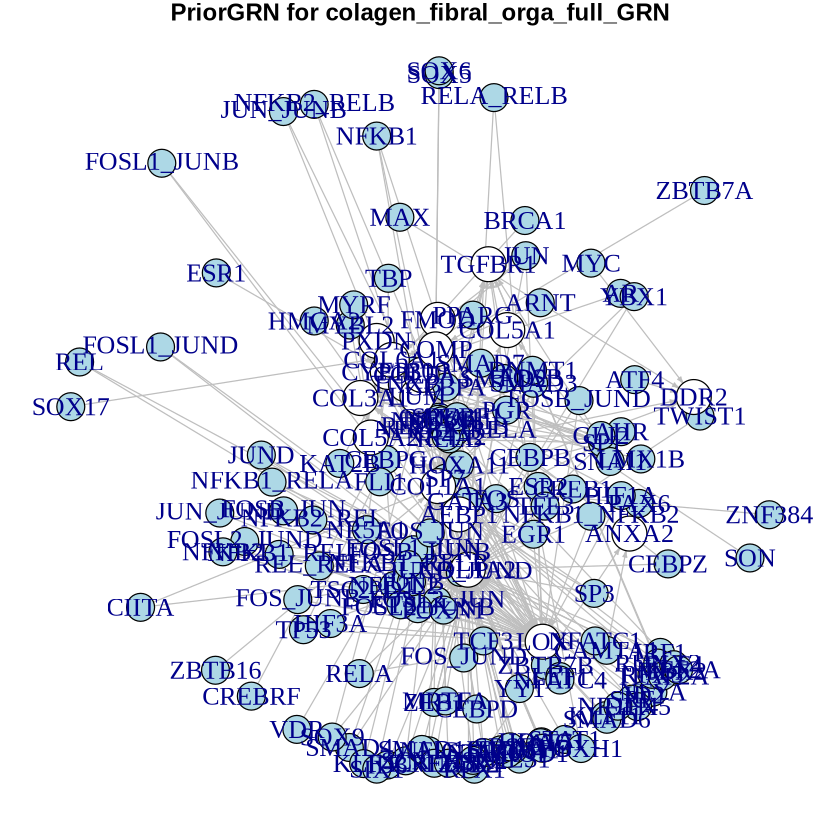

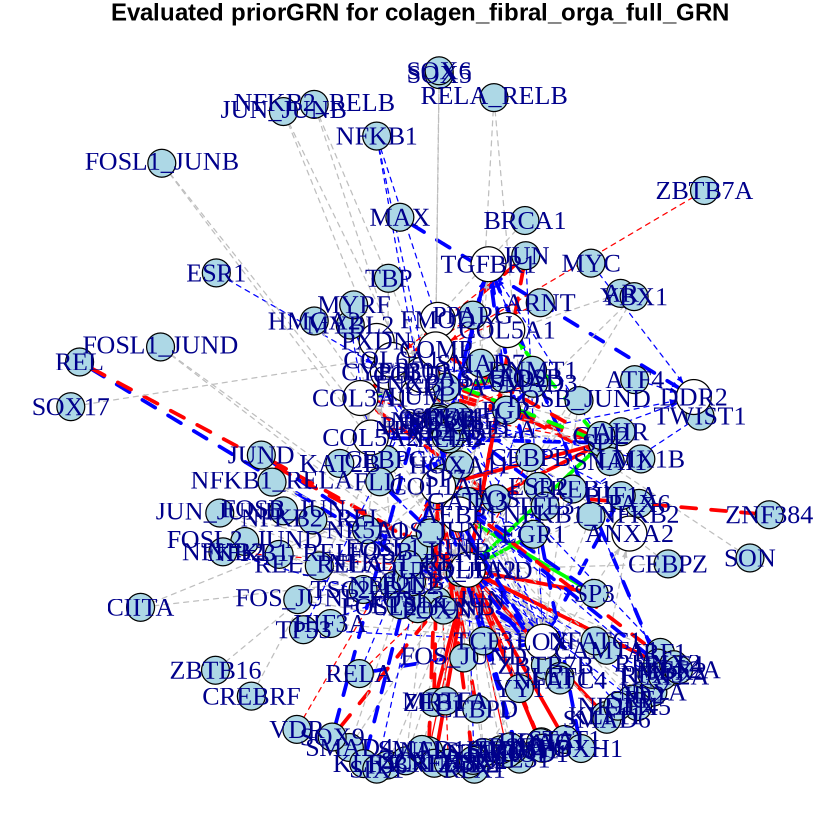

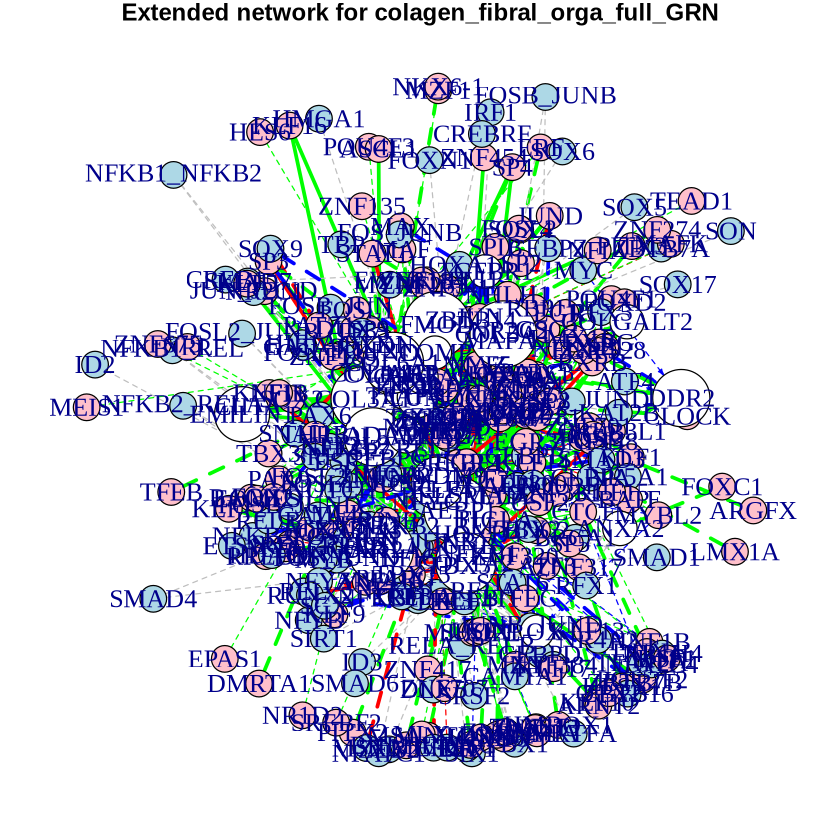

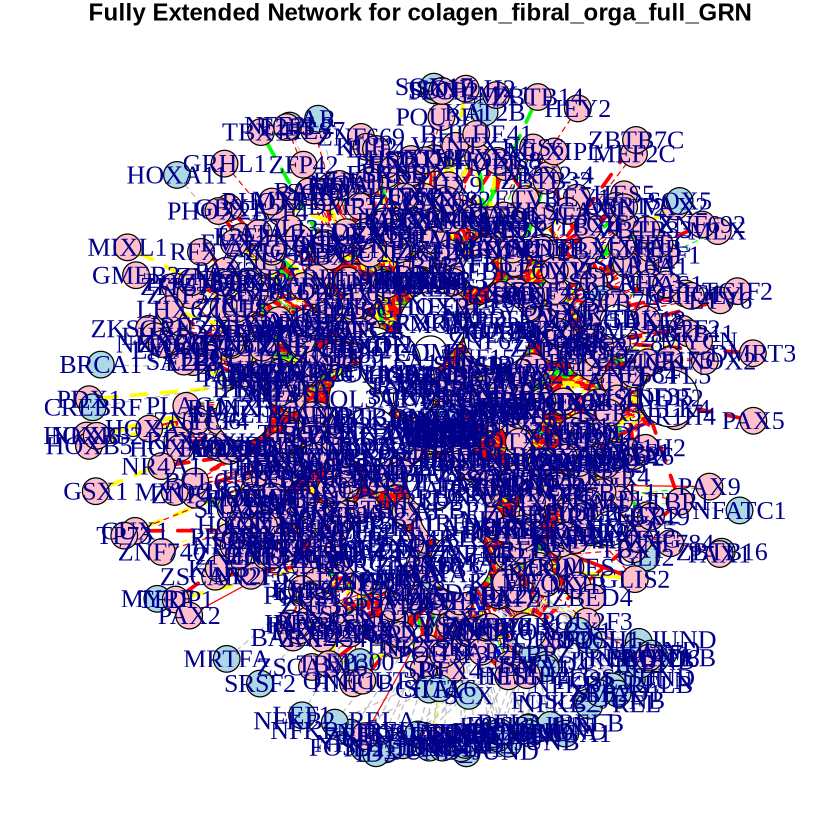

In [20]:
object_w_net<-draw_subNetwork_for_context(object=object_w_net, 
        gene_list= object_w_net@misc$peak_stats$gene %>% unique(),
        cluster.specific=TRUE,
        priorGRN=full_priorGRN,
        cluster="Fibroblast",
        context_name='colagen_fibral_orga_full_GRN',resolution=20,pointsize=50, sd=5, score=-0.5
        )

In [22]:
saveRDS(object_w_net, "objects_AVN_fibroblast/object_w_full_net.rds")

In [3]:
object_w_net <- readRDS("objects_AVN_fibroblast/object_w_full_net.rds")

In [23]:
str(object_w_net@misc$context_subNetwork, max.level=1)

List of 7
 $ colagen_fibral_orga                     :'data.frame':	935 obs. of  6 variables:
 $ colagen_fibral_orga_omni_path           :'data.frame':	927 obs. of  6 variables:
 $ colagen_fibral_orga_omni_path_cl_unsp   :'data.frame':	927 obs. of  6 variables:
 $ colagen_fibral_orga_omni_path_full_prior:'data.frame':	1138 obs. of  6 variables:
 $ colagen_fibral_orga_complete            :'data.frame':	2093 obs. of  6 variables:
 $ colagen_fibral_orga_ANXA2               :'data.frame':	42 obs. of  6 variables:
 $ colagen_fibral_orga_full_GRN            :'data.frame':	3310 obs. of  6 variables:


In [36]:
options(repr.plot.width=20, repr.plot.height=20)
final_graph.df <- object_w_net@misc$context_subNetwork[["colagen_fibral_orga_full_GRN"]]
show_colors <- c("red", "yellow", "green", "black")
final_graph.df<-final_graph.df[final_graph.df$color %in% show_colors,]
final_graph.df[final_graph.df$from %in% c("SP1", "JUNB"),]
final_graph.df[final_graph.df$from %in% c("JUNB"),]

,from,to,color,priorTF,reg_type,in.prom
,<chr>,<chr>,<chr>,<lgl>,<int>,<int>
COLGALT2.30,JUNB,COLGALT2,red,FALSE,2,1
FMOD.38,SP1,FMOD,green,FALSE,1,1
COL3A1.11,SP1,COL3A1,red,TRUE,2,1
COL3A1.63,JUNB,COL3A1,yellow,FALSE,2,1
PXDN.37,JUNB,PXDN,yellow,FALSE,2,1
PXDN.54,SP1,PXDN,green,FALSE,2,1
CYP1B1.12,SP1,CYP1B1,red,TRUE,2,3
CYP1B1.82,JUNB,CYP1B1,red,FALSE,2,1
COL5A2.95,JUNB,COL5A2,green,FALSE,2,3


,from,to,color,priorTF,reg_type,in.prom
,<chr>,<chr>,<chr>,<lgl>,<int>,<int>
COLGALT2.30,JUNB,COLGALT2,red,FALSE,2,1
COL3A1.63,JUNB,COL3A1,yellow,FALSE,2,1
PXDN.37,JUNB,PXDN,yellow,FALSE,2,1
CYP1B1.82,JUNB,CYP1B1,red,FALSE,2,1
COL5A2.95,JUNB,COL5A2,green,FALSE,2,3
ADAMTS2.82,JUNB,ADAMTS2,yellow,FALSE,2,3
TNXB.79,JUNB,TNXB,yellow,FALSE,2,3
COL1A2.29,JUNB,COL1A2,red,TRUE,2,1
TGFBR1.40,JUNB,TGFBR1,red,FALSE,2,1


In [95]:

object_w_net@misc$TF2motif[["SP1"]]

[1] "MA0079.5"

In [93]:
object_w_net@misc$TF2motif[["JUN"]]

[1] "MA1127.1" "MA1129.1" "MA0462.3" "MA0488.2" "MA0099.4" "MA1130.2" "MA1132.2"
[8] "MA1133.2"

In [94]:
object_w_net@misc$motif2TF[["MA1130.2"]]

[1] "FOSL2" "JUN"

In [90]:
object_w_net@misc$TF2motif[["FOSL2"]]

[1] "MA0478.2" "MA1130.2" "MA1131.2" "MA1138.2" "MA1139.2" "MA1144.2" "MA1145.2"

In [88]:
unique(final_graph.df$from)

[1] "GLI2"        "MYRF"        "SMAD7"       "CEBPZ"       "CIITA"      
 [6] "EP300"       "FOSB_JUN"    "FOSB_JUNB"   "FOSB_JUND"   "FOSL1_JUN"  
[11] "FOSL1_JUNB"  "FOSL1_JUND"  "FOSL2_JUN"   "FOSL2_JUNB"  "FOSL2_JUND" 
[16] "FOS_JUN"     "FOS_JUNB"    "FOS_JUND"    "FOXN1"       "HDAC1"      
[21] "HMGA1"       "ID2"         "ID3"         "IRF1"        "JUNB_JUND"  
[26] "JUN_JUNB"    "JUN_JUND"    "KAT7"        "NFKB1_NFKB2" "NFKB1_REL"  
[31] "NFKB1_RELA"  "NFKB1_RELB"  "NFKB2_REL"   "NFKB2_RELA"  "NFKB2_RELB" 
[36] "NOTCH1"      "RELA_RELB"   "REL_RELA"    "REL_RELB"    "SCX"        
[41] "SIRT1"       "SMAD1"       "SMAD4"       "SMAD6"       "STAT6"      
[46] "TSC22D1"     "YBX1"        "YY1"         "ZEB2"        "SP7"        
[51] "DLX5"        "LEF1"        "MRTFA"       "NFATC1"      "SRSF2"      
[56] "ZBTB16"

In [28]:
full_priorGRN_split[full_priorGRN_split$TF=="JUNB",]

gene,TF
<chr>,<chr>
COL1A2,JUNB
COL1A2,JUNB
COL1A2,JUNB
COL1A2,JUNB
COL1A2,JUNB
COL1A2,JUNB
COL1A2,JUNB
LOX,JUNB
LOX,JUNB


In [31]:
final_graph.df_split <- object_w_net@misc$context_subNetwork[["colagen_fibral_orga_full_GRN_split"]]

final_graph.df_notsplit <- object_w_net@misc$context_subNetwork[["colagen_fibral_orga_full_GRN"]]

In [33]:
final_graph.df_split[final_graph.df_split$from %in% c("JUNB"),]

,from,to,color,priorTF,reg_type,in.prom
,<chr>,<chr>,<chr>,<lgl>,<int>,<int>
COLGALT2.30,JUNB,COLGALT2,red,FALSE,2,1
COL3A1.63,JUNB,COL3A1,red,FALSE,2,1
PXDN.37,JUNB,PXDN,yellow,FALSE,2,1
CYP1B1.82,JUNB,CYP1B1,red,FALSE,2,1
COL5A2.95,JUNB,COL5A2,green,FALSE,2,3
LOX.5,JUNB,LOX,blue,TRUE,2,1
ADAMTS2.82,JUNB,ADAMTS2,yellow,FALSE,2,3
TNXB.79,JUNB,TNXB,yellow,FALSE,2,3
COL1A2.10,JUNB,COL1A2,red,TRUE,2,1


[1] "COL5A2 0.975200108208759"  "COL1A2 0.859625884128735" 
[3] "COL5A1 0.0014043212140769" "COL1A1 0.675323388588423" 
 [1] "red"   "red"   "green" "red"   "red"   "red"   "red"   "red"   "red"  
[10] "red"   "red"   "red"   "red"   "red"   "red"   "red"   "red"   "red"  
[19] "red"   "red"   "red"   "green" "red"   "red"   "red"   "red"   "red"  
[28] "red"   "green" "red"   "red"   "red"   "red"   "red"   "red"   "red"  
[37] "red"   "red"   "red"  
IGRAPH 46fce39 DN-- 38 39 -- 
+ attr: name (v/c), color (e/c), priorTF (e/l), reg_type (e/n), in.prom
| (e/n)
+ edges from 46fce39 (vertex names):
 [1] SMAD3  ->COL5A2 CEBPB  ->COL1A2 EGR1   ->COL1A2 FOSB   ->COL1A2
 [5] JUN    ->COL1A2 JUNB   ->COL1A2 JUND   ->COL1A2 FOSL1  ->COL1A2
 [9] FOSL2  ->COL1A2 FOS    ->COL1A2 GATA4  ->COL1A2 KLF11  ->COL1A2
[13] MYB    ->COL1A2 NEUROD1->COL1A2 NFIC   ->COL1A2 NFKB2  ->COL1A2
[17] REL    ->COL1A2 RELA   ->COL1A2 RUNX2  ->COL1A2 SMAD2  ->COL1A2
[21] SOX9   ->COL1A2 SP1    ->COL1A2 SP3    ->COL1A

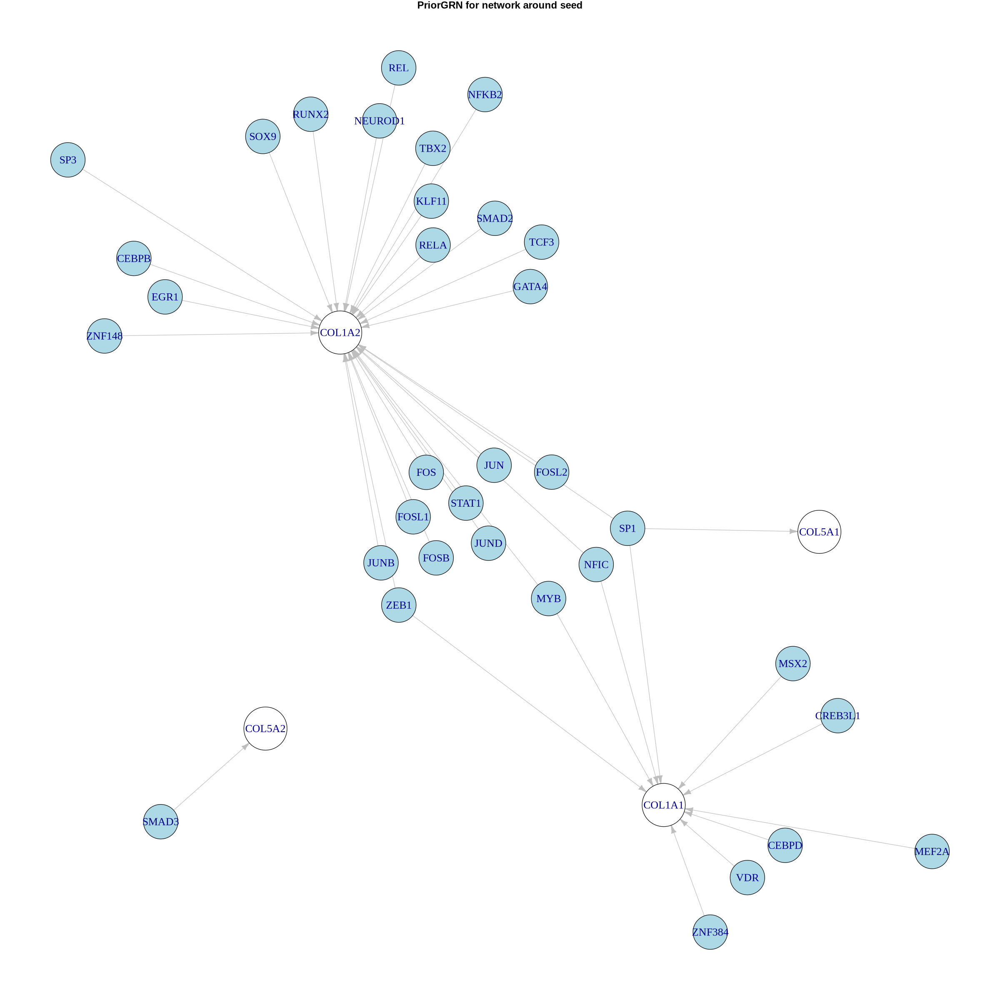

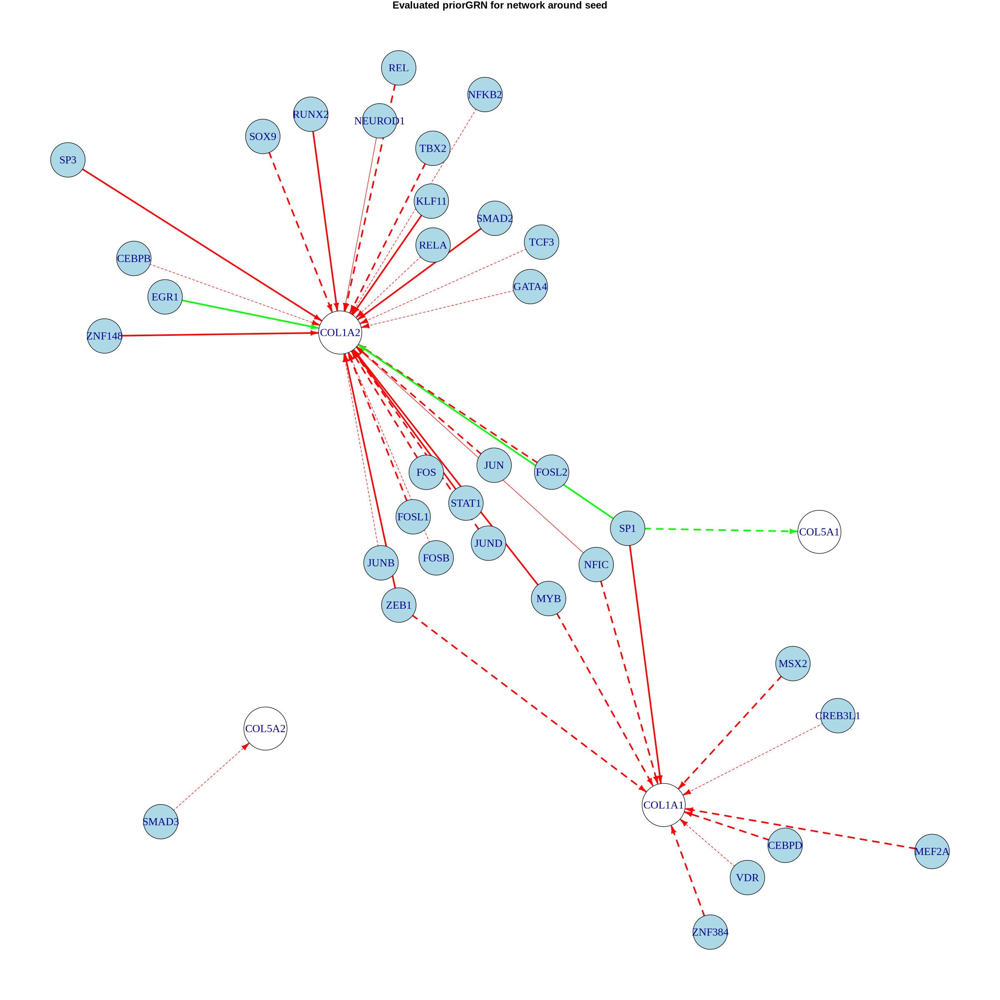

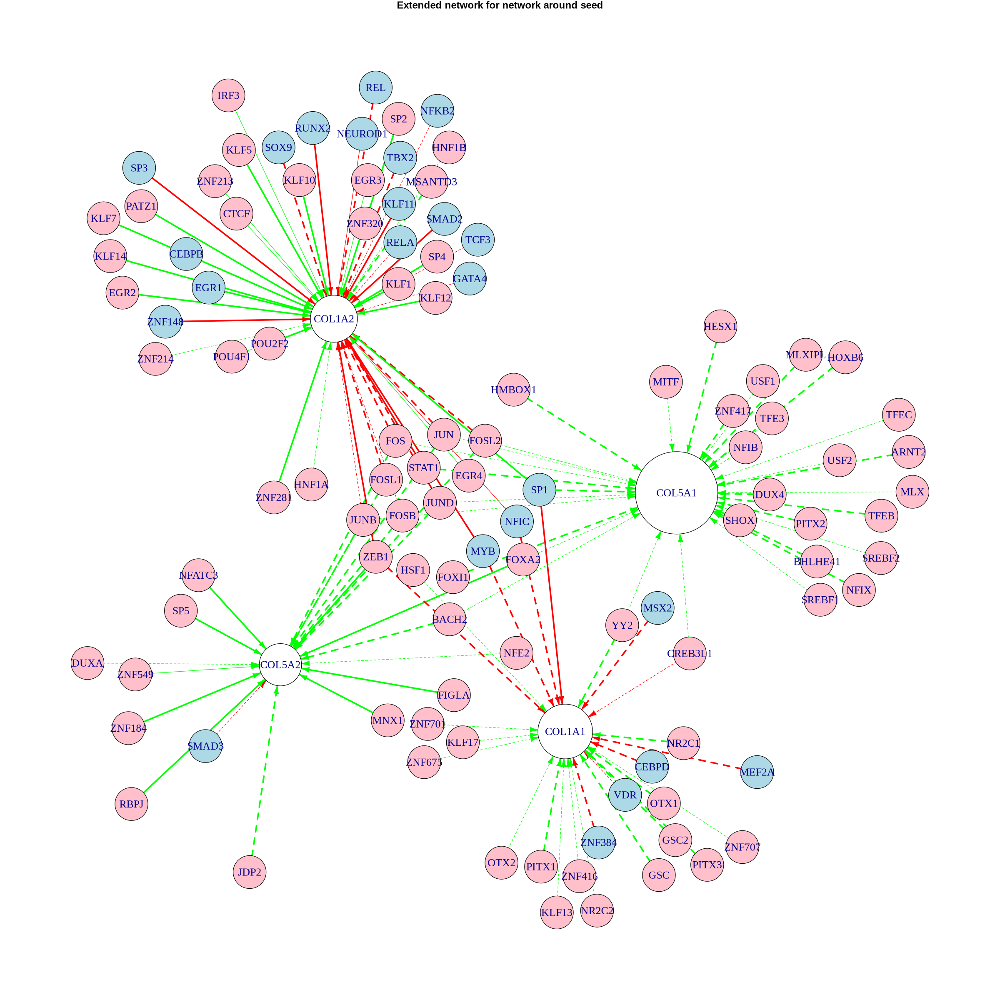

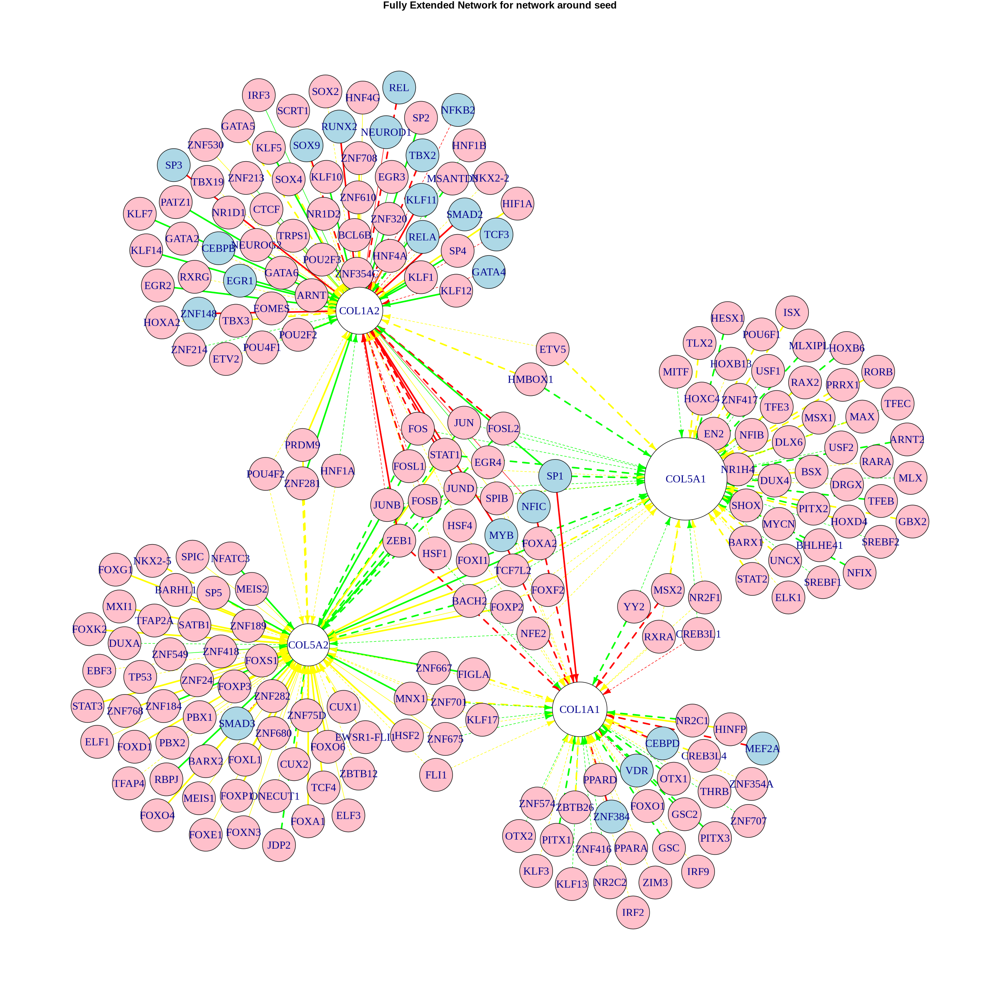

In [36]:
options(repr.plot.width=20, repr.plot.height=20)
final_graph.df <- object_w_net@misc$context_subNetwork[["colagen_fibral_orga_full_GRN_split"]]
show_colors <- c("red", "yellow", "green", "black")
final_graph.df<-final_graph.df[final_graph.df$color %in% show_colors,]
# final_graph.df<-final_graph.df[final_graph.df$reg_type==1,]
#final_graph.df<-final_graph.df[final_graph.df$in.prom==3,]
final_graph.df<-final_graph.df[(final_graph.df$color !="red" | final_graph.df$priorTF  ),]
# final_graph.df<-final_graph.df[final_graph.df$to %in% c("ADAMTS2", "TNXB","COL1A1","COL1A2", "COL5A2", "COL5A1", "COL3A1"),]
final_graph.df<-final_graph.df[final_graph.df$to %in% c("COL1A1","COL1A2", "COL5A2", "COL5A1"),]

final_graph<-igraph::graph_from_data_frame(final_graph.df, directed = TRUE)

plot_graph(final_graph,  width = 35, height = 35)

[1] "COL5A2 0.917695041366795"   "COL1A2 0.932834523395648"  
[3] "COL5A1 0.00010364461800758" "COL1A1 0.894011957401917"  
 [1] "blue"  "blue"  "red"   "blue"  "red"   "green" "blue"  "blue"  "red"  
[10] "red"   "red"   "red"   "red"   "red"   "red"   "red"   "blue"  "red"  
[19] "red"   "red"   "red"   "blue"  "red"   "red"   "red"   "blue"  "blue" 
[28] "blue"  "blue"  "blue"  "blue"  "red"   "red"   "blue"  "red"   "green"
[37] "red"   "blue"  "red"   "red"   "red"   "blue"  "blue"  "blue"  "blue" 
[46] "red"   "red"   "green" "blue"  "red"   "red"   "blue"  "blue"  "blue" 
[55] "red"   "red"   "red"   "blue"  "blue"  "red"   "blue"  "blue"  "blue" 
[64] "blue"  "blue"  "blue"  "red"   "blue"  "blue"  "red"   "blue"  "red"  
[73] "red"  
IGRAPH 8f4fc05 DN-- 59 73 -- 
+ attr: name (v/c), color (e/c), priorTF (e/l), reg_type (e/n), in.prom
| (e/n)
+ edges from 8f4fc05 (vertex names):
 [1] MYBL2  ->COL5A2 PGR    ->COL5A2 SMAD3  ->COL5A2 SP1    ->COL5A2
 [5] CEBPB  ->COL1A2 EGR1   ->C

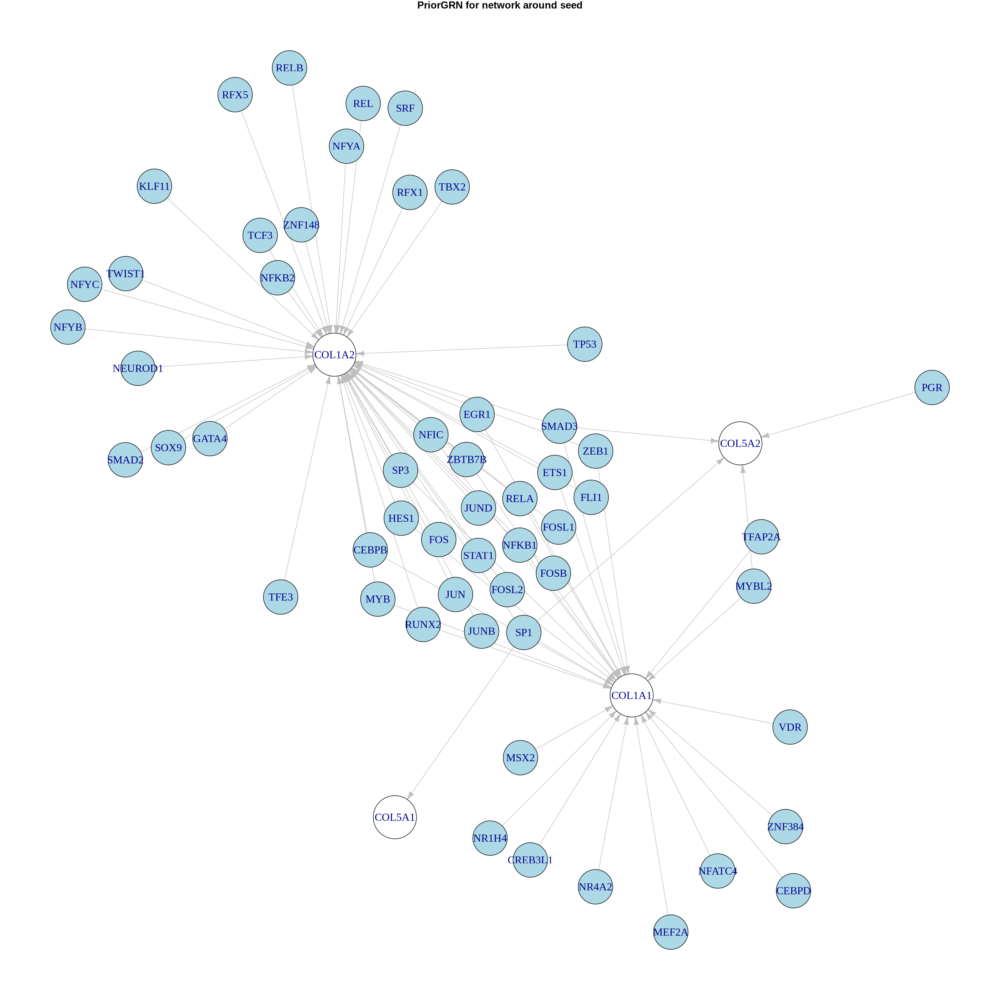

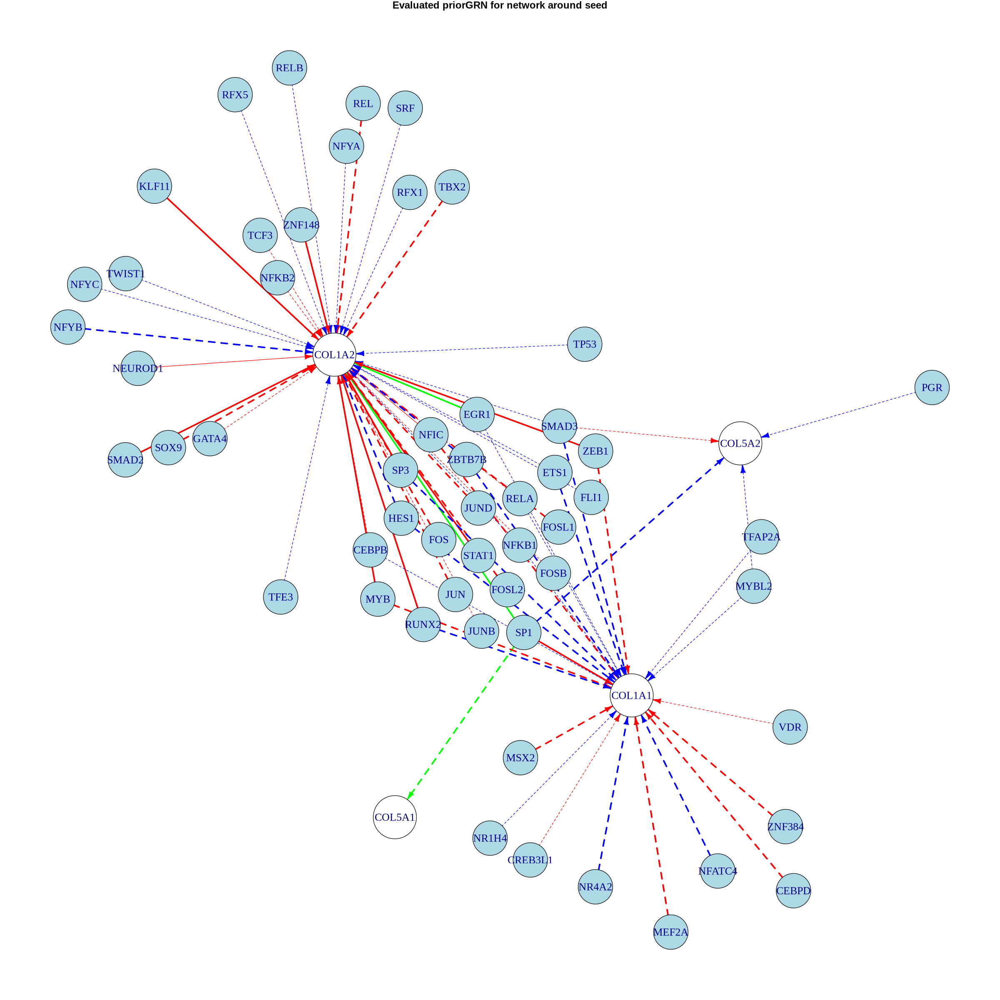

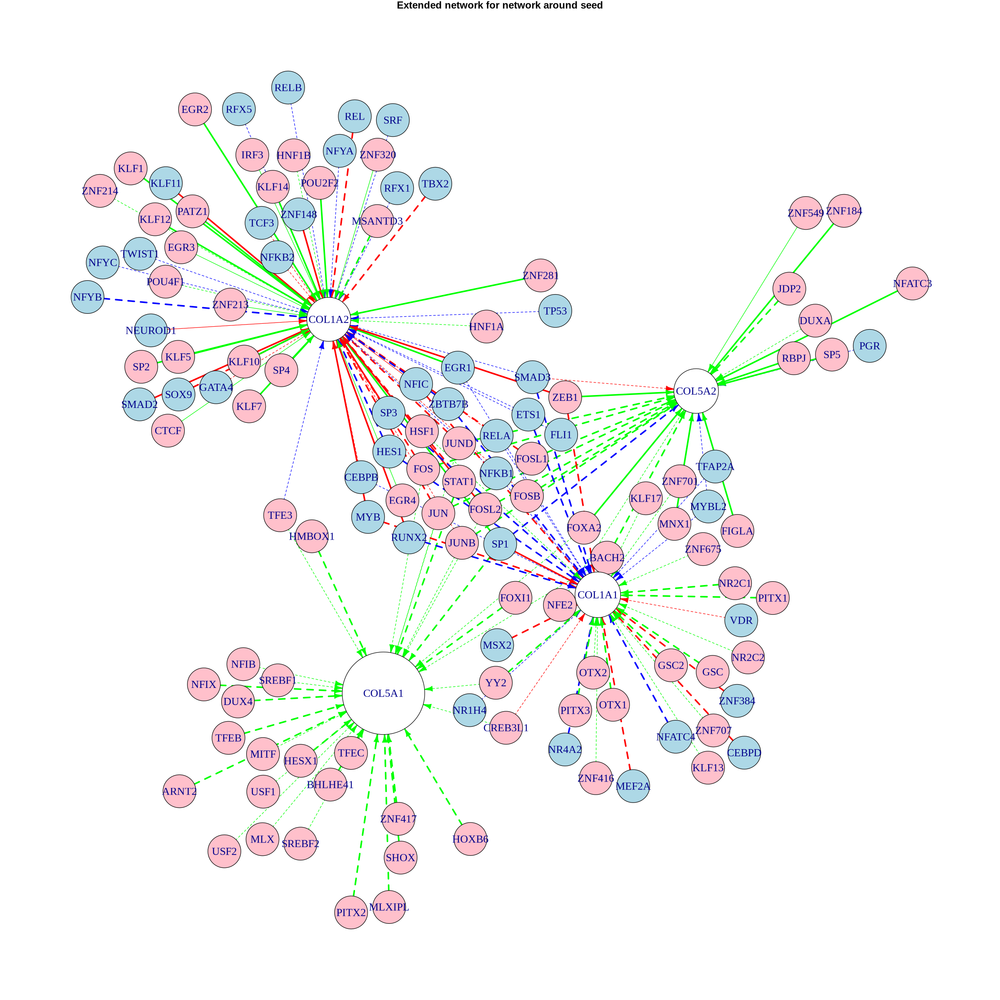

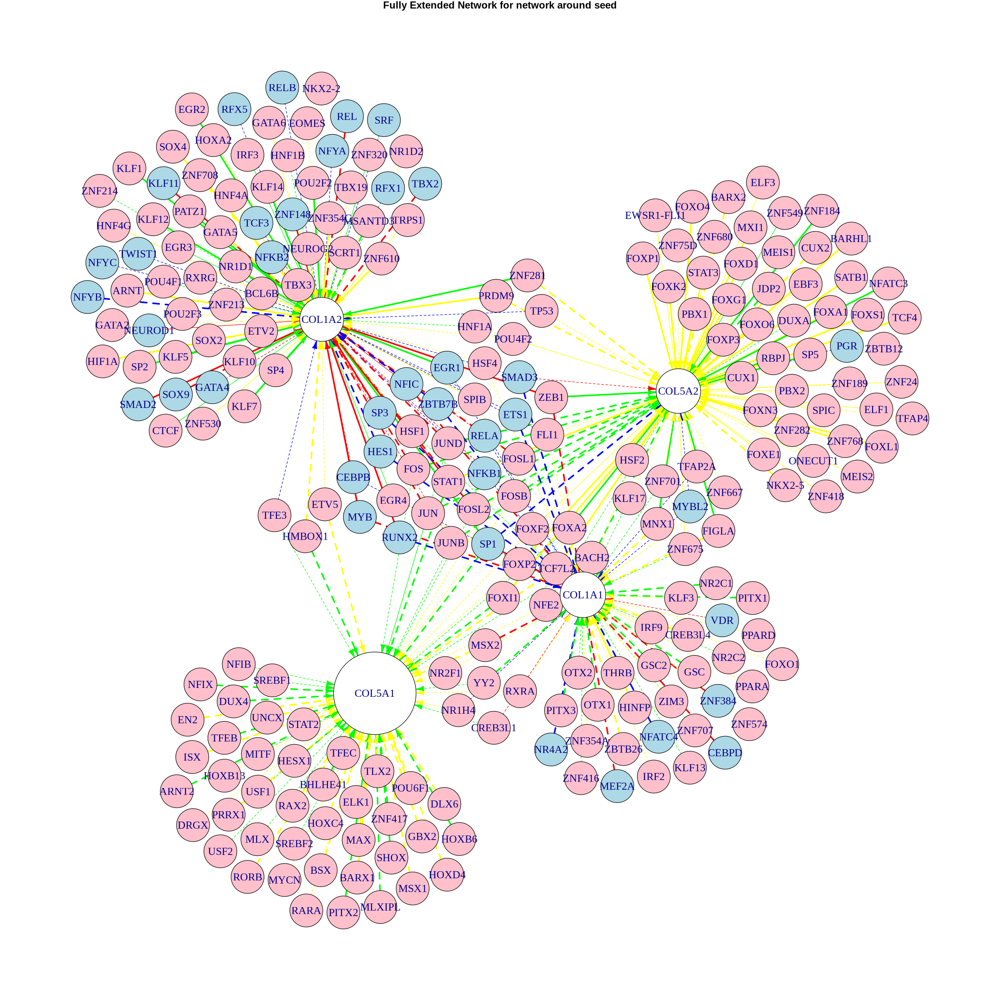

In [35]:
options(repr.plot.width=20, repr.plot.height=20)
final_graph.df <- object_w_net@misc$context_subNetwork[["colagen_fibral_orga_full_GRN_split"]]
show_colors <- c("red", "yellow", "green", "black", "blue")
final_graph.df<-final_graph.df[final_graph.df$color %in% show_colors,]
# final_graph.df<-final_graph.df[final_graph.df$reg_type==1,]
#final_graph.df<-final_graph.df[final_graph.df$in.prom==3,]
final_graph.df<-final_graph.df[(final_graph.df$color !="red" | final_graph.df$priorTF  ),]
# final_graph.df<-final_graph.df[final_graph.df$to %in% c("ADAMTS2", "TNXB","COL1A1","COL1A2", "COL5A2", "COL5A1", "COL3A1"),]
final_graph.df<-final_graph.df[final_graph.df$to %in% c("COL1A1","COL1A2", "COL5A2", "COL5A1"),]

final_graph<-igraph::graph_from_data_frame(final_graph.df, directed = TRUE)

plot_graph(final_graph,  width = 35, height = 35)

[1] "COL5A2 0.984296454267615"    "COL1A2 0.998271397249878"   
[3] "COL5A1 8.30238213387506e-09" "COL1A1 0.530386110176778"   
 [1] "blue"  "blue"  "blue"  "green" "blue"  "blue"  "blue"  "red"   "red"  
[10] "red"   "red"   "blue"  "blue"  "blue"  "blue"  "blue"  "blue"  "blue" 
[19] "red"   "red"   "blue"  "green" "red"   "blue"  "red"   "blue"  "blue" 
[28] "blue"  "blue"  "red"   "red"   "green" "blue"  "blue"  "blue"  "blue" 
[37] "blue"  "blue"  "blue"  "blue"  "blue"  "blue"  "blue"  "blue"  "red"  
[46] "blue"  "blue"  "blue" 
IGRAPH f06dc8c DN-- 40 48 -- 
+ attr: name (v/c), color (e/c), priorTF (e/l), reg_type (e/n), in.prom
| (e/n)
+ edges from f06dc8c (vertex names):
 [1] MYBL2  ->COL5A2 PGR    ->COL5A2 SP1    ->COL5A2 EGR1   ->COL1A2
 [5] ETS1   ->COL1A2 FLI1   ->COL1A2 HES1   ->COL1A2 KLF11  ->COL1A2
 [9] MYB    ->COL1A2 NEUROD1->COL1A2 NFIC   ->COL1A2 NFKB1  ->COL1A2
[13] NFYA   ->COL1A2 NFYB   ->COL1A2 NFYC   ->COL1A2 RELB   ->COL1A2
[17] RFX1   ->COL1A2 RFX5   ->COL1A

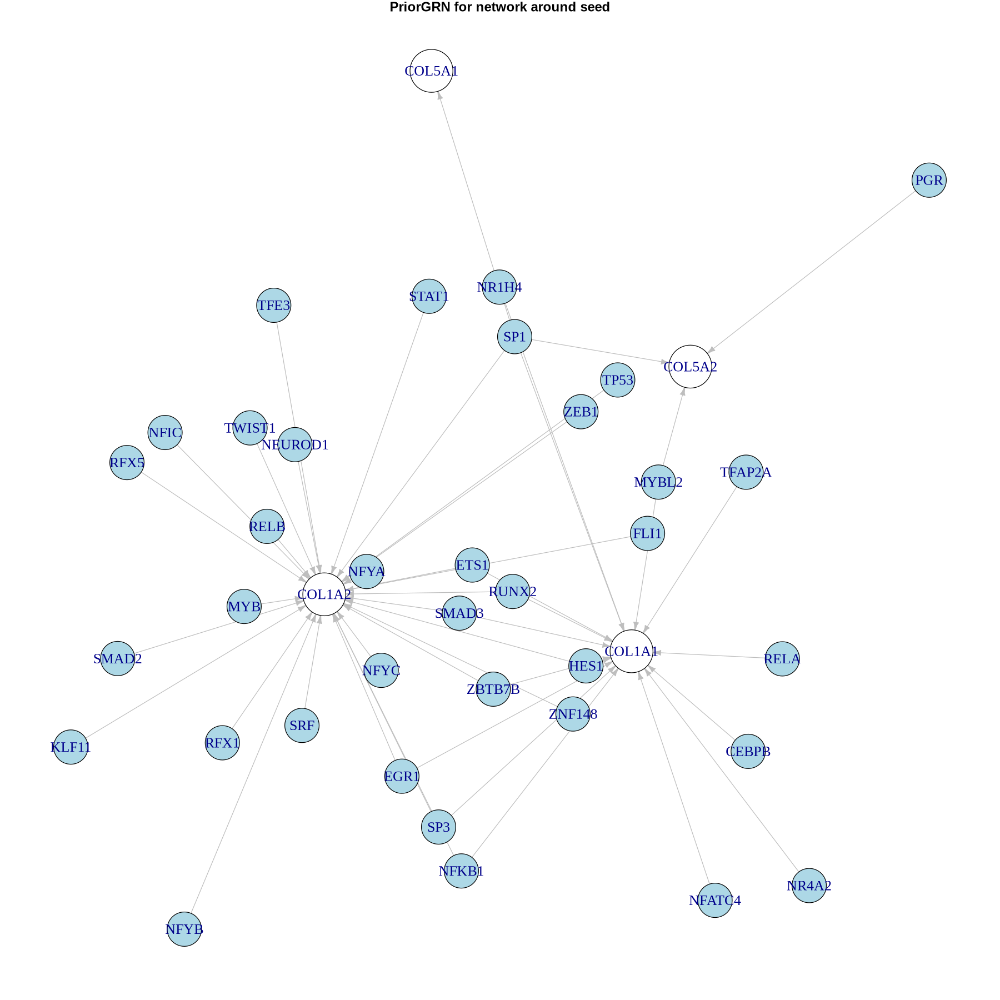

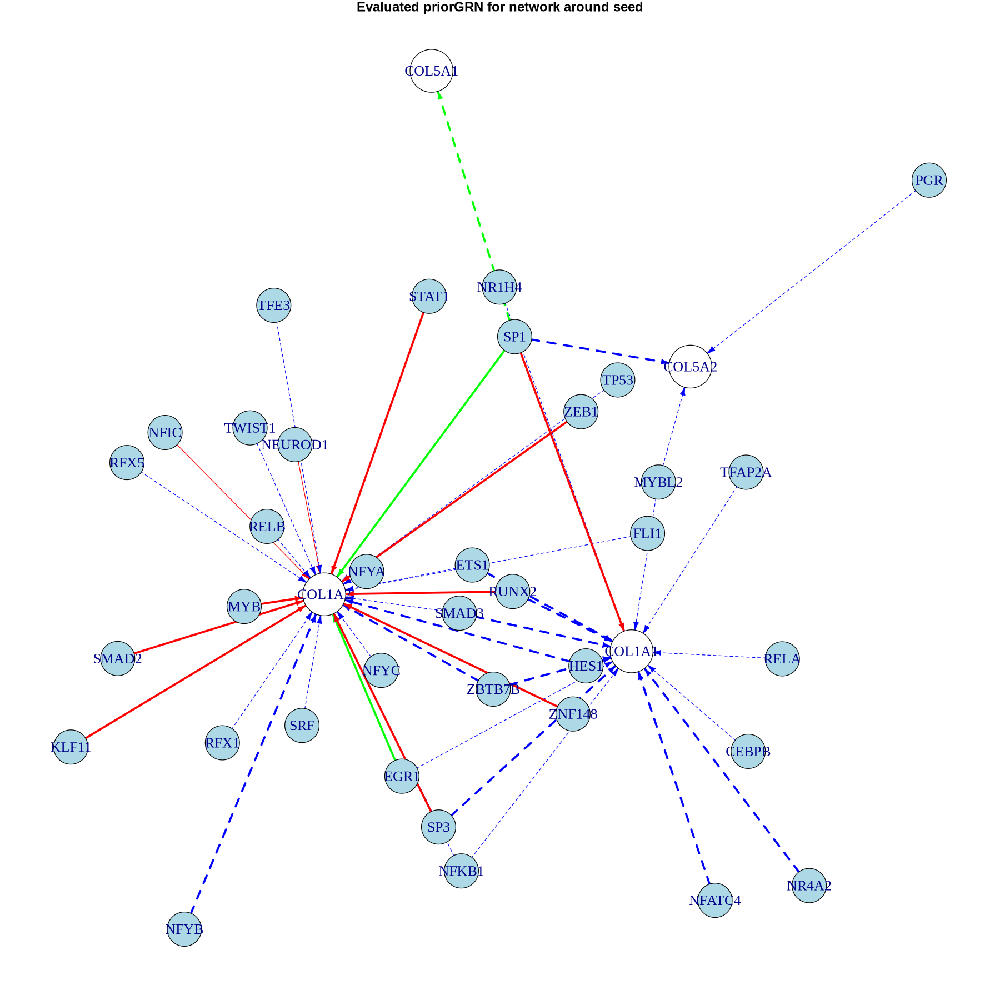

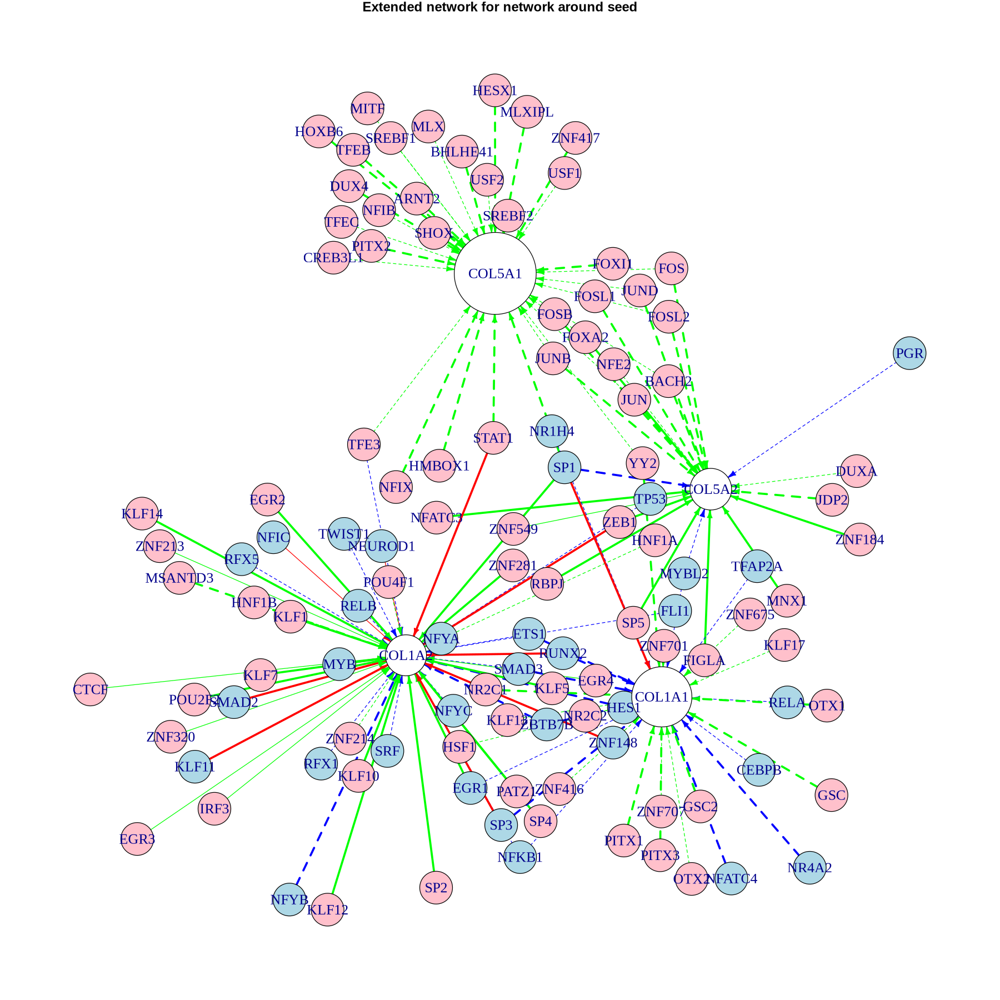

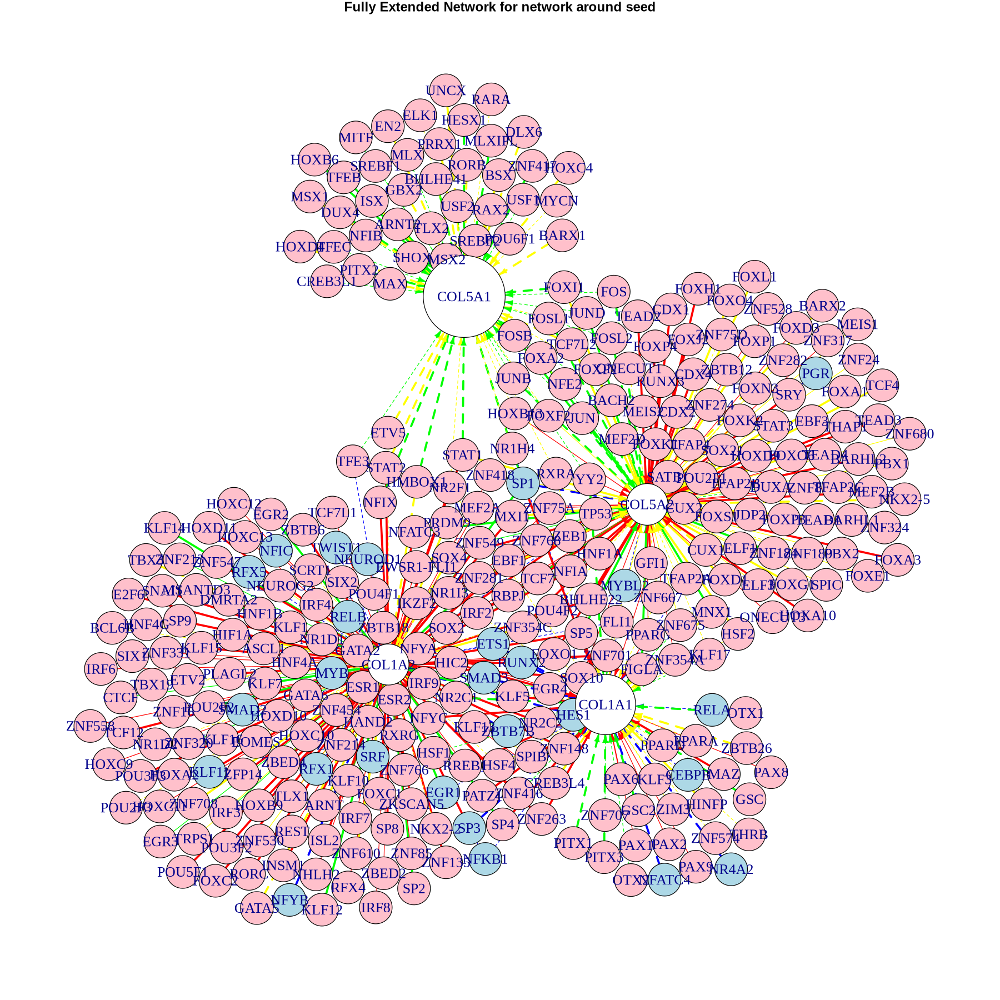

In [65]:
options(repr.plot.width=15, repr.plot.height=15)
final_graph.df <- object_w_net@misc$context_subNetwork[["colagen_fibral_orga_full_GRN"]]
show_colors <- c("red", "yellow", "green", "black", "blue")
final_graph.df<-final_graph.df[final_graph.df$color %in% show_colors,]
# final_graph.df<-final_graph.df[final_graph.df$reg_type==1,]
#final_graph.df<-final_graph.df[final_graph.df$in.prom==3,]
final_graph.df<-final_graph.df[(final_graph.df$color !="red" | final_graph.df$reg_type==1  ),]
# final_graph.df<-final_graph.df[final_graph.df$to %in% c("ADAMTS2", "TNXB","COL1A1","COL1A2", "COL5A2", "COL5A1", "COL3A1"),]
final_graph.df<-final_graph.df[final_graph.df$to %in% c("COL1A1","COL1A2", "COL5A2", "COL5A1"),]

final_graph<-igraph::graph_from_data_frame(final_graph.df, directed = TRUE)

plot_graph(final_graph,  width = 30, height = 30)

In [12]:
options(repr.plot.width=15, repr.plot.height=15)
final_graph.df <- object_w_net@misc$context_subNetwork[["colagen_fibral_orga_full_GRN"]]
show_colors <- c("red", "yellow", "green", "black", "blue", "gray")
final_graph.df<-final_graph.df[final_graph.df$color %in% show_colors,]
# final_graph.df<-final_graph.df[final_graph.df$reg_type==1,]
#final_graph.df<-final_graph.df[final_graph.df$in.prom==3,]
final_graph.df<-final_graph.df[(final_graph.df$color !="red" | final_graph.df$reg_type==1  ),]
# final_graph.df<-final_graph.df[final_graph.df$to %in% c("ADAMTS2", "TNXB","COL1A1","COL1A2", "COL5A2", "COL5A1", "COL3A1"),]
final_graph.df<-final_graph.df[final_graph.df$to %in% c("COL1A1","COL1A2", "COL5A2", "COL5A1"),]


In [16]:
full_priorGRN <- read.csv("/nfs/home/students/m.back/swarm/backend/calc_multiome_scores/multiome_tf_regulation/notebooks_pipeline/objects_AVN_fibroblast/gene_tf_relations_AVN_fibroblasts.csv")


In [ ]:
unique(full_priorGRN$TF)

[1] "HR"          "HTATIP2"     "SSRP1"       "TFAP2A"      "ZBTB16"     
  [6] "SP1"         "SP3"         "CAMTA1"      "STAT6"       "ESR1"       
 [11] "ESR2"        "FOXN1"       "HIF1A"       "RUNX1"       "TP53"       
 [16] "TTF1"        "WT1"         "GLI2"        "ZNF8"        "CEBPZ"      
 [21] "EGR1"        "LEF1"        "MLX"         "MYCN"        "NFYB"       
 [26] "CTCF"        "ERG"         "EWSR1"       "HMGA2"       "MAF"        
 [31] "SOX10"       "SOX9"        "SP7"         "ZNF219"      "ZNF250"     
 [36] "ZNF263"      "CEBPB"       "CEBPD"       "CIITA"       "CREB3L1"    
 [41] "DLX5"        "ETS1"        "HES1"        "MEF2A"       "MRTFA"      
 [46] "MSX2"        "MYB"         "MYBL2"       "NFATC1"      "NFATC4"     
 [51] "NFIC"        "NFKB1"       "NOTCH1"      "NR1H4"       "NR4A2"      
 [56] "RELA"        "RUNX2"       "SCX"         "SMAD3"       "SMAD4"      
 [61] "SMAD7"       "SRSF2"       "VDR"         "YBX1"        "YY1"        
 [66] "ZBTB7B"      "ZEB1"        "ZNF384"      "EP300"       "FLI1"       
 [71] "FOSB_JUN"    "FOSB_JUNB"   "FOSB_JUND"   "FOSL1_JUN"   "FOSL1_JUNB" 
 [76] "FOSL1_JUND"  "FOSL2_JUN"   "FOSL2_JUNB"  "FOSL2_JUND"  "FOS_JUN"    
 [81] "FOS_JUNB"    "FOS_JUND"    "GATA4"       "HDAC1"       "HMGA1"      
 [86] "ID2"         "ID3"         "IRF1"        "JUN"         "JUNB"       
 [91] "JUNB_JUND"   "JUND"        "JUN_JUNB"    "JUN_JUND"    "KAT7"       
 [96] "KLF11"       "NEUROD1"     "NFKB1_NFKB2" "NFKB1_REL"   "NFKB1_RELA" 
[101] "NFKB1_RELB"  "NFKB2"       "NFKB2_REL"   "NFKB2_RELA"  "NFKB2_RELB" 
[106] "NFYA"        "NFYC"        "REL"         "RELA_RELB"   "RELB"       
[111] "REL_RELA"    "REL_RELB"    "RFX1"        "RFX5"        "SIRT1"      
[116] "SMAD1"       "SMAD2"       "SMAD6"       "SRF"         "STAT1"      
[121] "TBX2"        "TCF3"        "TFE3"        "TSC22D1"     "TWIST1"     
[126] "ZEB2"        "ZNF148"      "AIRE"        "ARID5A"      "BHLHE40"    
[131] "CEBPA"       "CEBPG"       "DLX2"        "EHF"         "ELF3"       
[136] "FOS"         "HAND2"       "HBP1"        "HEY1"        "HIVEP1"     
[141] "KAT5"        "MEF2C"       "NCOA2"       "NFAT5"       "NFIB"       
[146] "NONO"        "SNAI1"       "SNAI2"       "SOX17"       "SOX5"       
[151] "SOX6"        "TBX15"       "TFAP2E"      "FOSB"        "HOXA11"     
[156] "LMX1B"       "PPARG"       "MYC"         "FOXO1"       "SRY"        
[161] "VHL"         "MYRF"        "PGR"         "SREBF1"      "NR2F1"      
[166] "CREBRF"      "SON"         "ZBTB7A"      "AHR"         "AR"         
[171] "ARNT"        "BRCA1"       "CREB1"       "KAT2B"       "NR5A1"      
[176] "PAX6"        "TBP"         "ATF4"        "MAX"         "NR1I2"      
[181] "DDIT3"       "TRPS1"       "USF1"        "EZH2"        "FOXA1"      
[186] "GATA3"       "MEOX1"       "RARA"        "RARG"        "TFAP2C"     
[191] "GSC"         "GLI1"        "DNMT1"       "HIF3A"       "E2F5"       
[196] "ELF4"        "RARB"        "ETS2"        "FOXD2"       "GFI1"       
[201] "HNF4A"       "IRF2"        "IRF8"        "MYOD1"       "NKX2-5"     
[206] "POU6F2"      "SPI1"        "STAT5A"      "TBPL1"       "TFAP4"      
[211] "TWIST2"      "USF2"        "PITX2"       "NFE2L2"      "ARID4A"     
[216] "ATF2"        "BCL3"        "CTNNB1"      "CXXC1"       "DNMT3A"     
[221] "E2F1"        "E2F3"        "E2F4"        "ELF1"        "GABPA"      
[226] "GRHL3"       "GTF2IRD1"    "HINFP"       "JARID2"      "MBD2"       
[231] "NCOR1"       "NR4A1"       "PAX5"        "PAX8"        "PDX1"       
[236] "POU3F2"      "STAT3"       "STAT5B"      "TAF1"        "TFDP1"      
[241] "THRA"        "THRB"        "VENTX"       "VSX2"        "XBP1"       
[246] "ZBTB17"      "ZBTB33"      "ETV4"        "MKX"         "SIX4"       
[251] "TCF15"       "HSF1"        "KLF2"        "FOXO3"       "POU2F1"     
[256] "POU2F2"      "ATF1"        "ATF7"        "BCL11B"      "KDM5B"      
[261] "NKX2-1"      "NR3C1"       "PAX3"        "P

In [ ]:
final_graph.df$priorTF <- TRUE where final_graph.df$from %in% c("JUN", "JUNB", "JUND")

,from,to,color,priorTF,reg_type,in.prom
,<chr>,<chr>,<chr>,<lgl>,<int>,<int>
COL5A2.1,GLI2,COL5A2,gray,TRUE,2,1
COL5A2.2,MYBL2,COL5A2,blue,TRUE,2,1
COL5A2.3,MYRF,COL5A2,gray,TRUE,2,1
COL5A2.4,PGR,COL5A2,blue,TRUE,2,1
COL5A2.6,SMAD7,COL5A2,gray,TRUE,2,1
COL5A2.7,SP1,COL5A2,blue,TRUE,2,3
COL5A2.12,ZNF354C,COL5A2,red,FALSE,1,3
COL5A2.13,EWSR1-FLI1,COL5A2,yellow,FALSE,1,1
COL5A2.14,FOXG1,COL5A2,yellow,FALSE,1,3


[1] "COL5A2 0.994952908835303"    "COL1A2 0.997486978865378"   
[3] "COL5A1 7.62973004587942e-08" "COL1A1 0.265286496891371"   
 [1] "green" "red"   "red"   "red"   "red"   "red"   "red"   "green" "red"  
[10] "red"   "red"   "red"   "green" "red"  
IGRAPH 88bd506 DN-- 15 14 -- 
+ attr: name (v/c), color (e/c), priorTF (e/l), reg_type (e/n), in.prom
| (e/n)
+ edges from 88bd506 (vertex names):
 [1] EGR1   ->COL1A2 KLF11  ->COL1A2 MYB    ->COL1A2 NEUROD1->COL1A2
 [5] NFIC   ->COL1A2 RUNX2  ->COL1A2 SMAD2  ->COL1A2 SP1    ->COL1A2
 [9] SP3    ->COL1A2 STAT1  ->COL1A2 ZEB1   ->COL1A2 ZNF148 ->COL1A2
[13] SP1    ->COL5A1 SP1    ->COL1A1


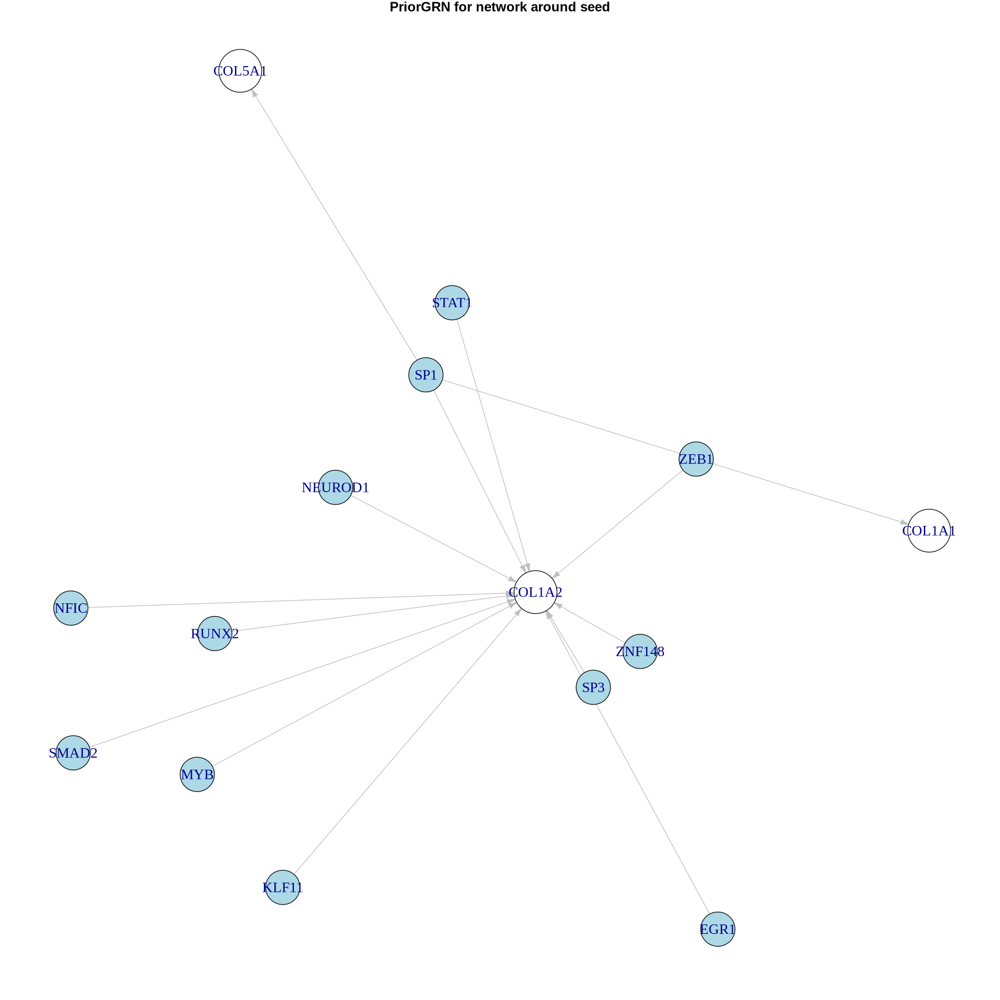

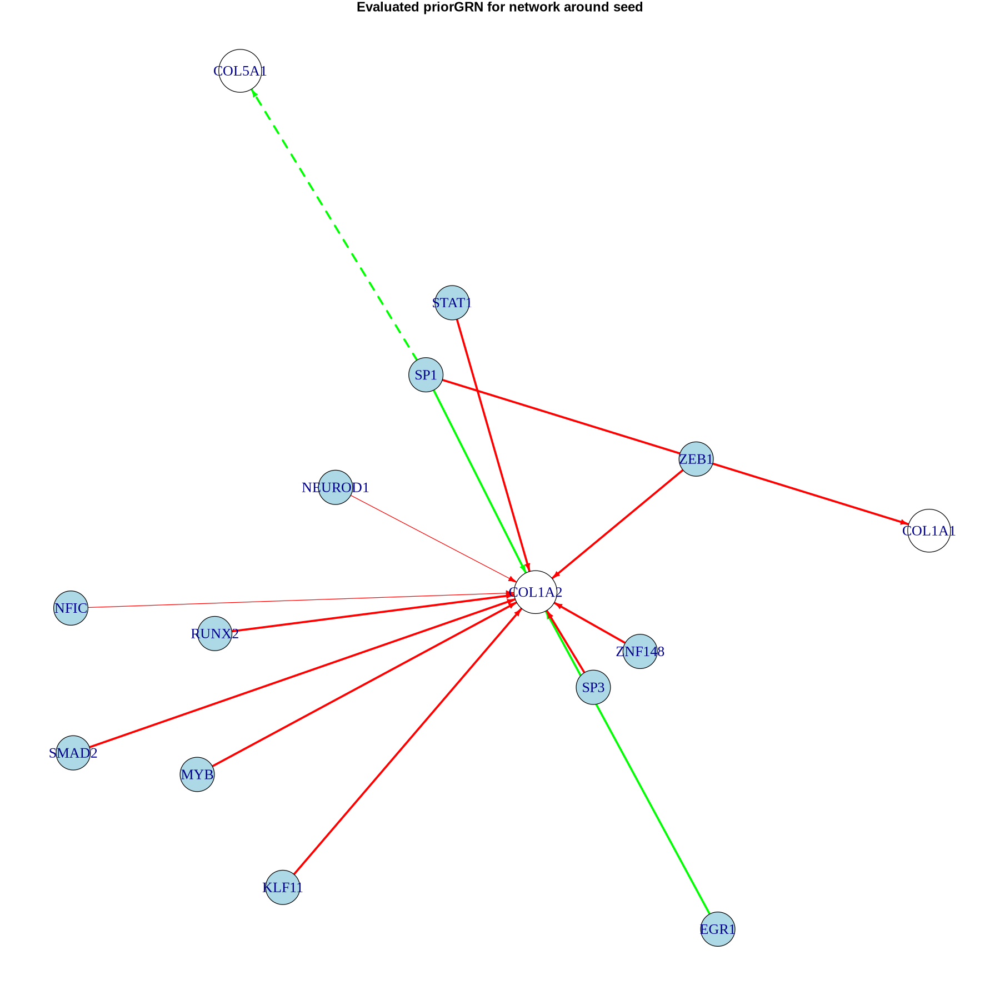

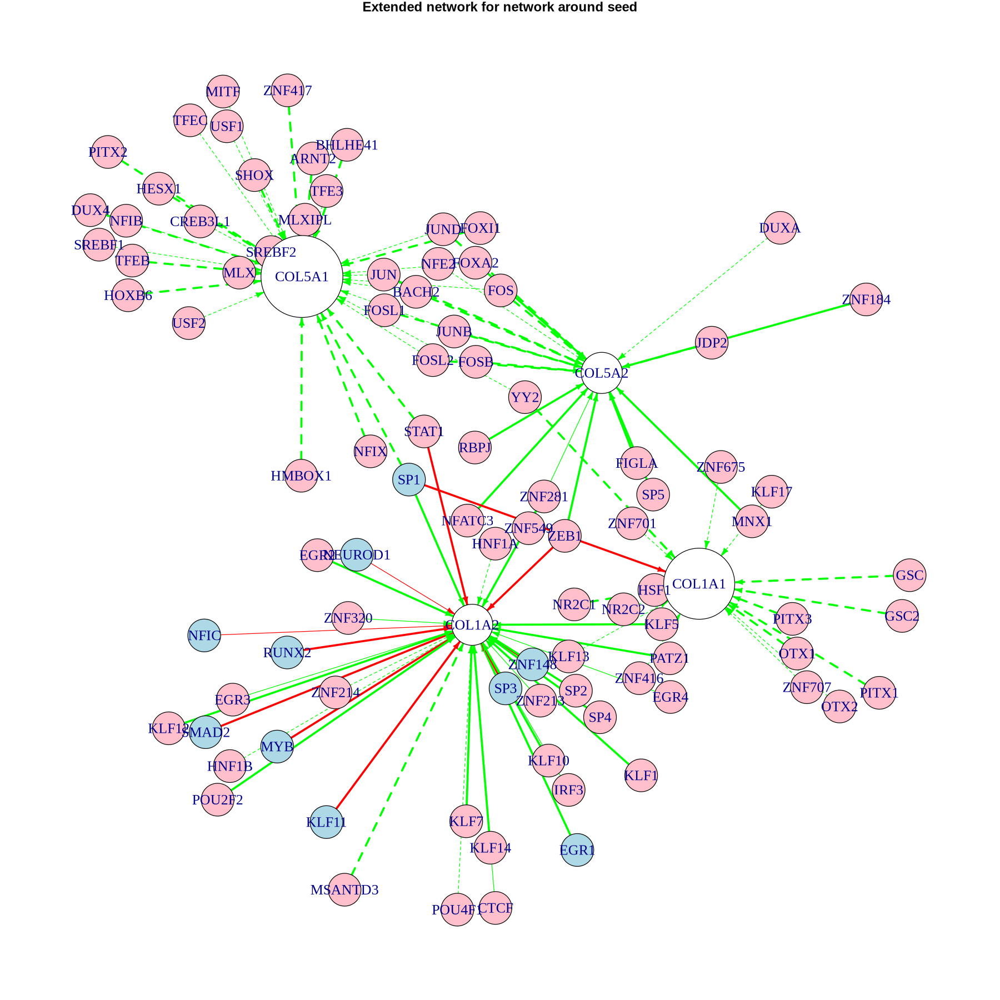

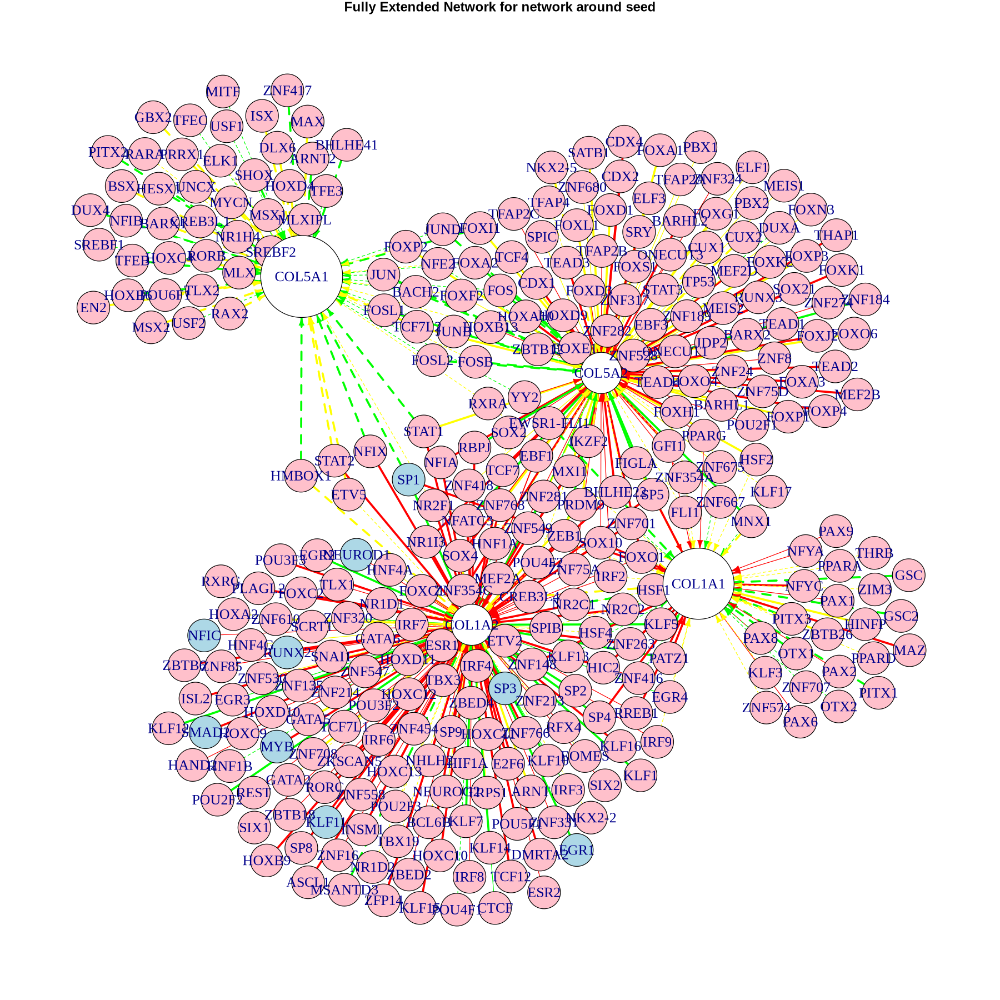

In [59]:
options(repr.plot.width=15, repr.plot.height=15)
final_graph.df <- object_w_net@misc$context_subNetwork[["colagen_fibral_orga_full_GRN"]]
show_colors <- c("red", "yellow", "green", "black")
final_graph.df<-final_graph.df[final_graph.df$color %in% show_colors,]
# final_graph.df<-final_graph.df[final_graph.df$reg_type==1,]
#final_graph.df<-final_graph.df[final_graph.df$in.prom==3,]
final_graph.df<-final_graph.df[(final_graph.df$color !="red" | final_graph.df$reg_type==1  ),]
# final_graph.df<-final_graph.df[final_graph.df$to %in% c("ADAMTS2", "TNXB","COL1A1","COL1A2", "COL5A2", "COL5A1", "COL3A1"),]
final_graph.df<-final_graph.df[final_graph.df$to %in% c("COL1A1","COL1A2", "COL5A2", "COL5A1"),]

final_graph<-igraph::graph_from_data_frame(final_graph.df, directed = TRUE)

plot_graph(final_graph,  width = 30, height = 30)

[1] "2026-04-30 10:58:18 CEST"
GRanges object with 2 ranges and 1 metadata column:
      seqnames            ranges strand |     score
         <Rle>         <IRanges>  <Rle> | <numeric>
  [1]     chr7 94267053-94267061      + |   12.3107
  [2]     chr7 94301183-94301191      - |   13.4532
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-30 10:58:18 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


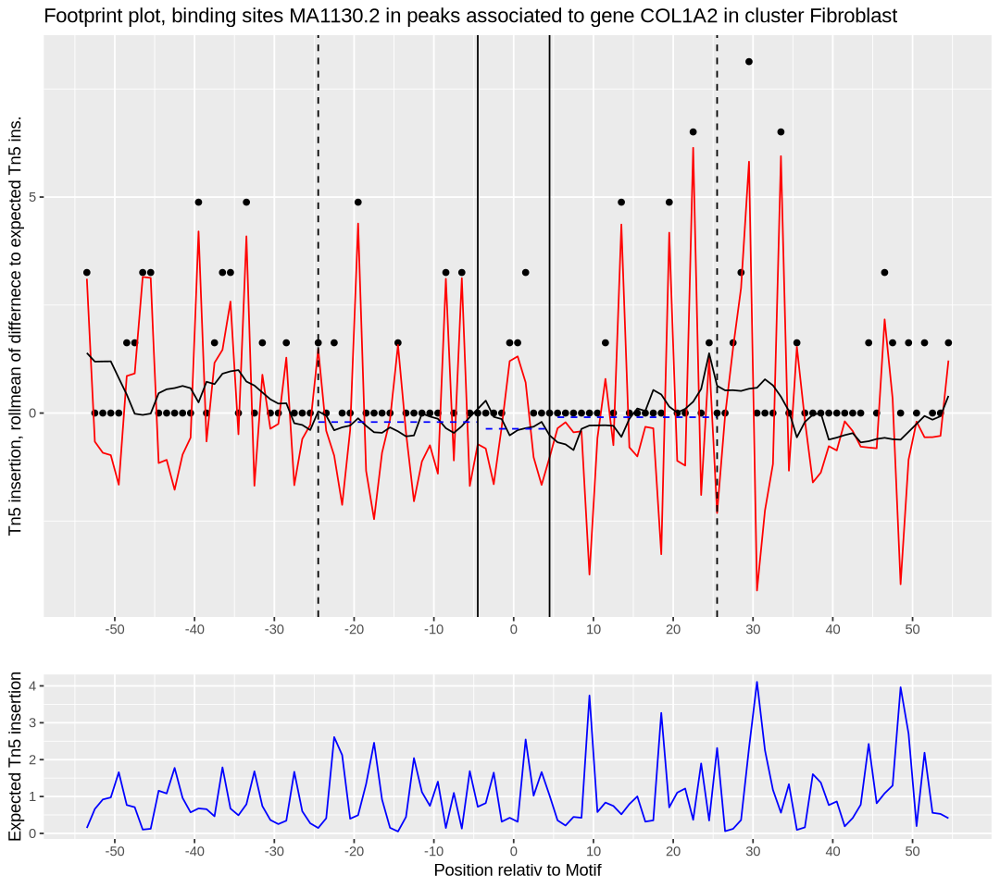

In [44]:
options(repr.plot.width=9, repr.plot.height=8)
footprint_plots_by_TF(object=object_w_net, gene='COL1A2', cluster="Fibroblast", motif_id="MA1130.2", path=NULL)

TF provided, plotting all motifs for TF



[1] "2026-04-30 12:47:01 CEST"
GRanges object with 3 ranges and 1 metadata column:
      seqnames              ranges strand |     score
         <Rle>           <IRanges>  <Rle> | <numeric>
  [1]     chr9 134546059-134546067      - |   15.9318
  [2]     chr9 134724480-134724488      - |   16.0106
  [3]     chr9 134735480-134735488      + |   15.0104
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Warning message:
"The `slot` argument of `GetAssayData()` is deprecated as of SeuratObject 5.0.0.
ℹ Please use the `layer` argument instead."
Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-30 12:47:04 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


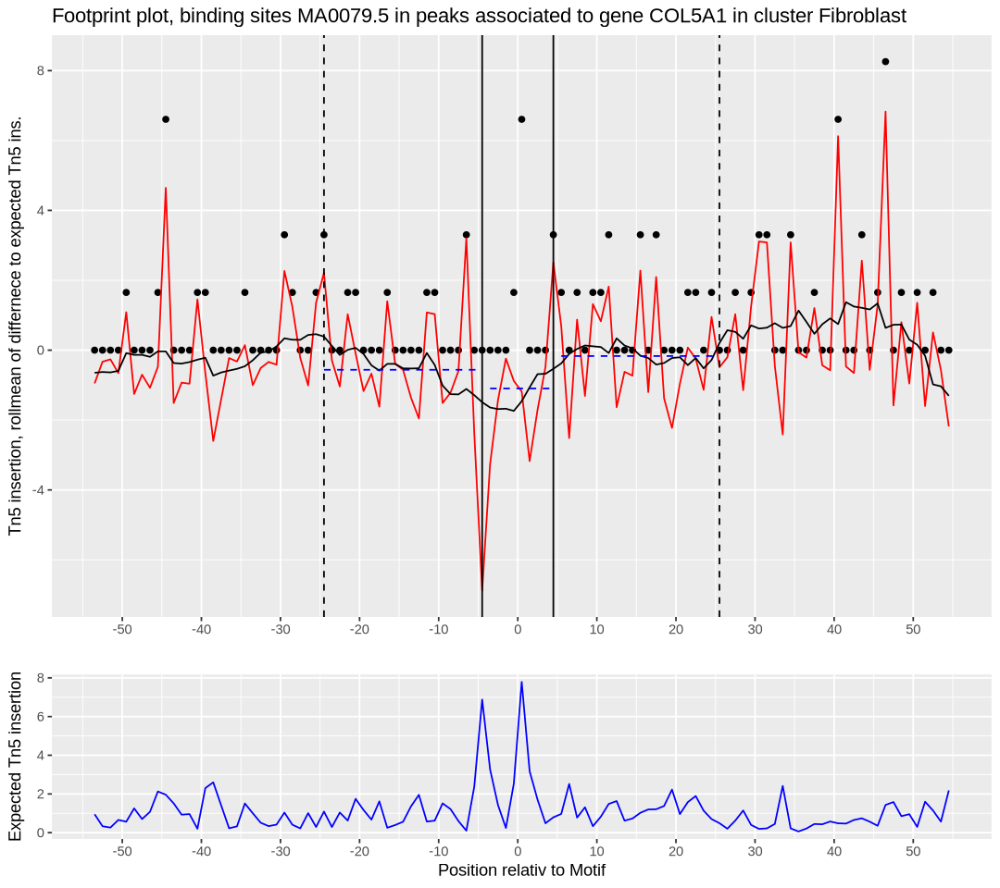

In [16]:
options(repr.plot.width=9, repr.plot.height=8)
footprint_plots_by_TF(object=object_w_net, gene='COL5A1', cluster="Fibroblast", TF="SP1", path=NULL)

[1] "2026-04-30 10:55:11 CEST"
GRanges object with 6 ranges and 1 metadata column:
      seqnames              ranges strand |     score
         <Rle>           <IRanges>  <Rle> | <numeric>
  [1]     chr2 189076810-189076818      + |   11.8444
  [2]     chr2 189076810-189076818      - |   14.1208
  [3]     chr2 189210374-189210382      + |   14.8221
  [4]     chr2 189210374-189210382      - |   12.5120
  [5]     chr2 189286423-189286431      + |   14.1208
  [6]     chr2 189286423-189286431      - |   11.8444
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-30 10:55:11 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


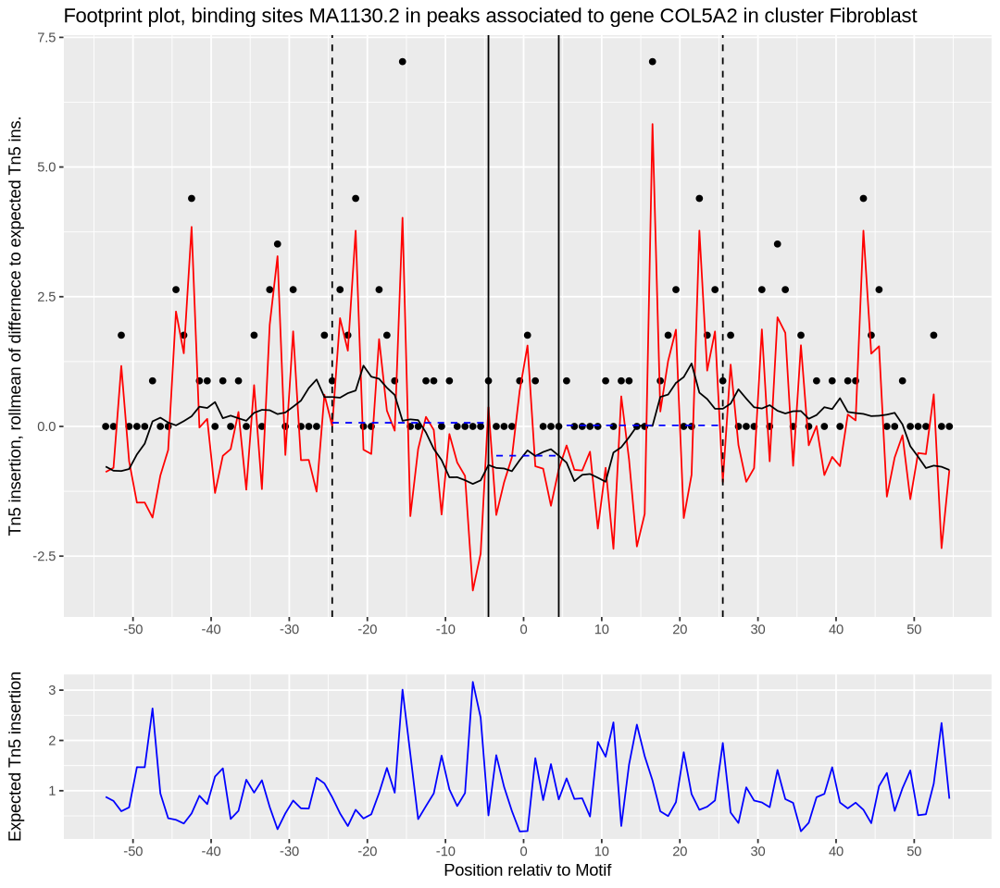

In [43]:
options(repr.plot.width=9, repr.plot.height=8)
footprint_plots_by_TF(object=object_w_net, gene='COL5A2', cluster="Fibroblast", motif_id="MA1130.2", path=NULL)

TF provided, plotting all motifs for TF



[1] "2026-04-30 10:59:29 CEST"
GRanges object with 4 ranges and 1 metadata column:
      seqnames            ranges strand |     score
         <Rle>         <IRanges>  <Rle> | <numeric>
  [1]     chr7 94394342-94394350      + |   17.6598
  [2]     chr7 94394363-94394371      + |   17.6598
  [3]     chr7 94348184-94348192      + |   17.6598
  [4]     chr7 94348408-94348416      + |   16.0106
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-30 10:59:29 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


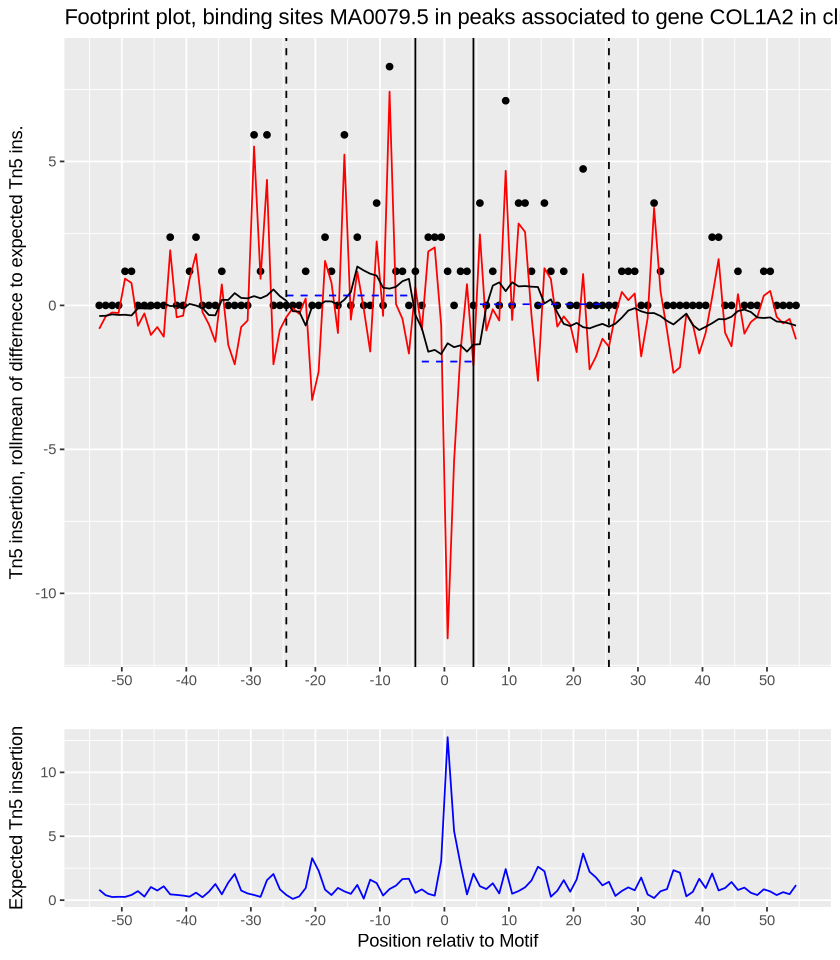

In [46]:
options(repr.plot.width=7, repr.plot.height=8)
footprint_plots_by_TF(object=object_w_net, gene='COL1A2', cluster="Fibroblast", TF="SP1", path=NULL)

In [5]:
object_w_net@misc$TF2motif[["SP1"]]

[1] "MA0079.5"

TF provided, plotting all motifs for TF



[1] "2026-04-30 11:32:29 CEST"
GRanges object with 1 range and 1 metadata column:
      seqnames            ranges strand |     score
         <Rle>         <IRanges>  <Rle> | <numeric>
  [1]     chr7 94394753-94394762      + |   14.0378
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-30 11:32:29 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


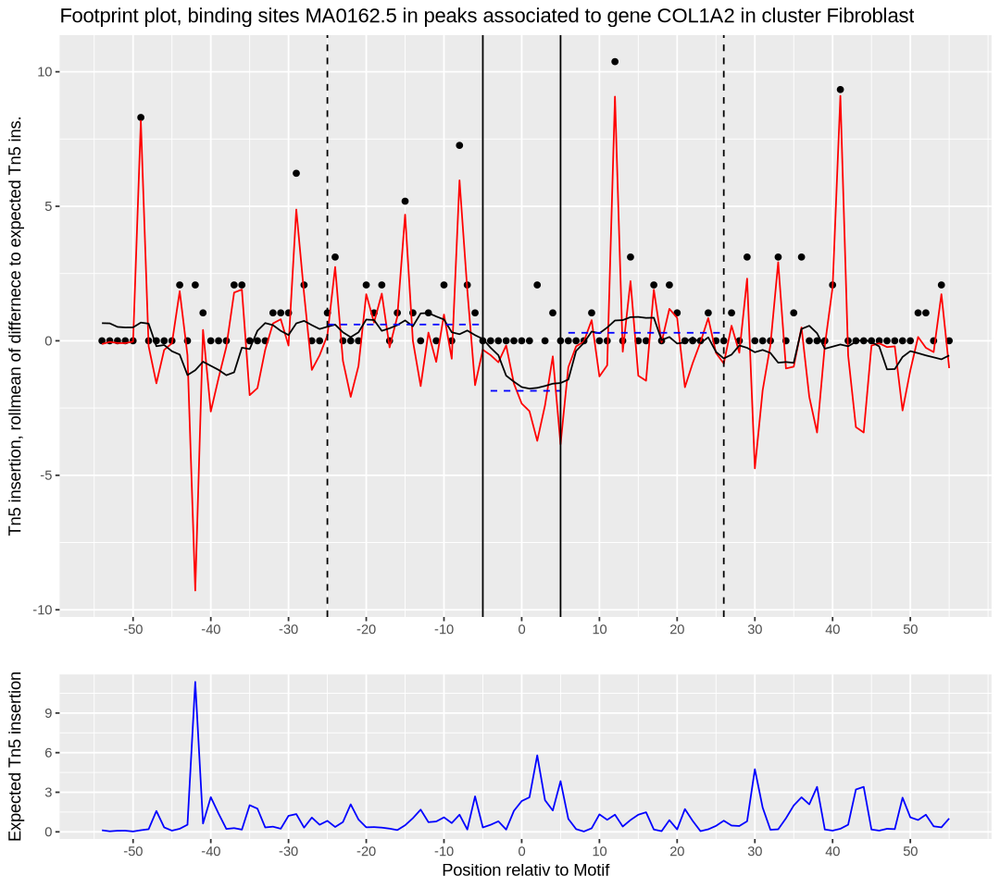

In [49]:
options(repr.plot.width=9, repr.plot.height=8)
footprint_plots_by_TF(object=object_w_net, gene='COL1A2', cluster="Fibroblast", TF="EGR1", path=NULL)

TF provided, plotting all motifs for TF



[1] "2026-04-30 10:52:57 CEST"
GRanges object with 3 ranges and 1 metadata column:
      seqnames              ranges strand |     score
         <Rle>           <IRanges>  <Rle> | <numeric>
  [1]     chr9 134546059-134546067      - |   15.9318
  [2]     chr9 134724480-134724488      - |   16.0106
  [3]     chr9 134735480-134735488      + |   15.0104
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-30 10:52:58 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


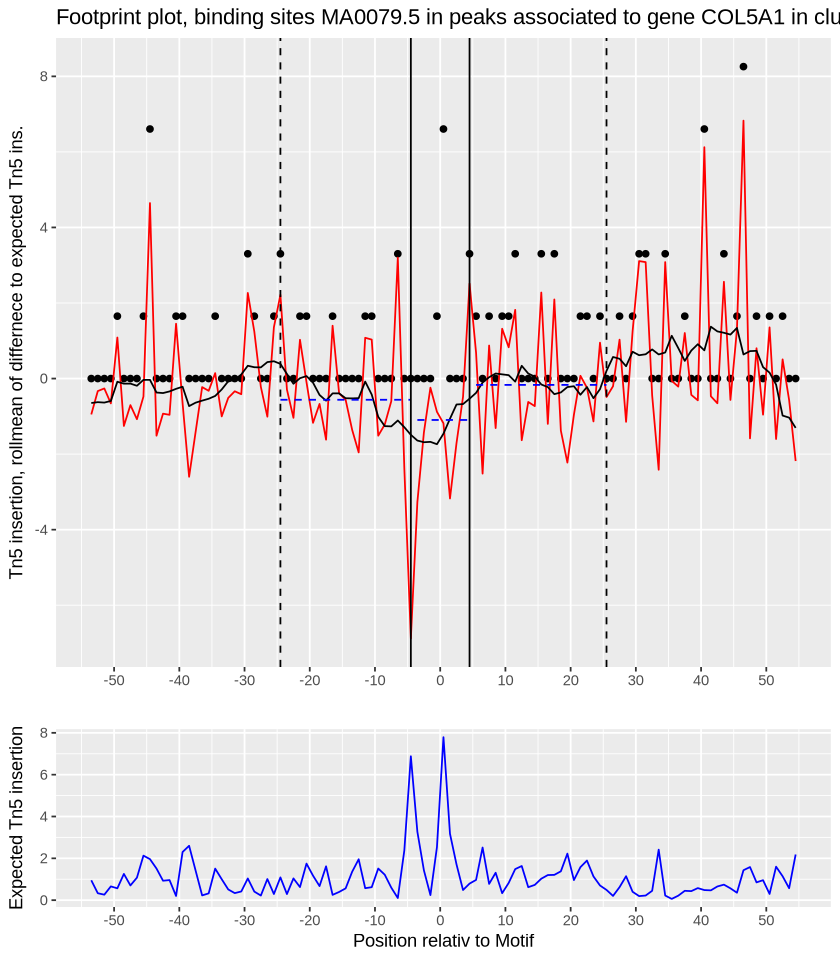

In [42]:
options(repr.plot.width=7, repr.plot.height=8)
footprint_plots_by_TF(object=object_w_net, gene='COL5A1', cluster="Fibroblast", TF="SP1", path=NULL)

TF provided, plotting all motifs for TF



[1] "2026-04-30 10:36:47 CEST"
GRanges object with 2 ranges and 1 metadata column:
      seqnames            ranges strand |     score
         <Rle>         <IRanges>  <Rle> | <numeric>
  [1]     chr7 94266488-94266497      + |   11.2833
  [2]     chr7 94266488-94266497      - |   11.5621
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-30 10:36:47 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] "2026-04-30 10:36:47 CEST"
GRanges object with 2 ranges and 1 metadata column:
      seqnames            ranges strand |     score
         <Rle>         <IRanges>  <Rle> | <numeric>
  [1]     chr7 94301183-94301191      + |   12.3387
  [2]     chr7 94301183-94301191      - |   13.3424
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


... (16 outputs left out)

Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-30 10:36:50 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 6
[1] "2 3"


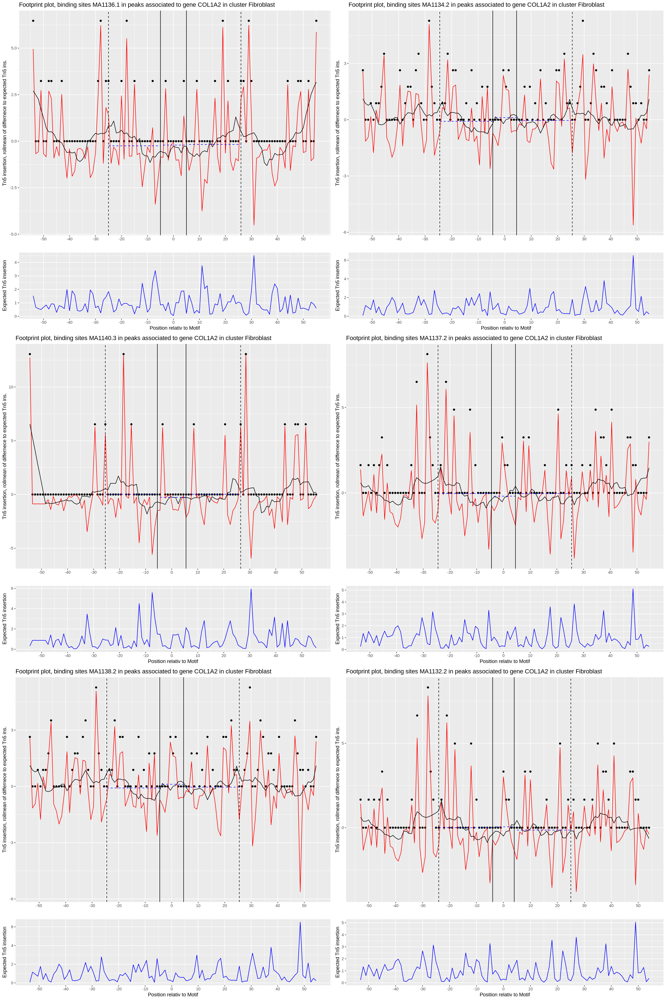

In [41]:
options(repr.plot.width=20, repr.plot.height=30)
footprint_plots_by_TF(object=object_w_net, gene='COL1A2', cluster="Fibroblast", TF="JUNB", path=NULL)

TF provided, plotting all motifs for TF



[1] "2026-04-30 08:44:05 CEST"
GRanges object with 4 ranges and 1 metadata column:
      seqnames            ranges strand |     score
         <Rle>         <IRanges>  <Rle> | <numeric>
  [1]     chr7 94394342-94394350      + |   17.6598
  [2]     chr7 94394363-94394371      + |   17.6598
  [3]     chr7 94348184-94348192      + |   17.6598
  [4]     chr7 94348408-94348416      + |   16.0106
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-30 08:44:06 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


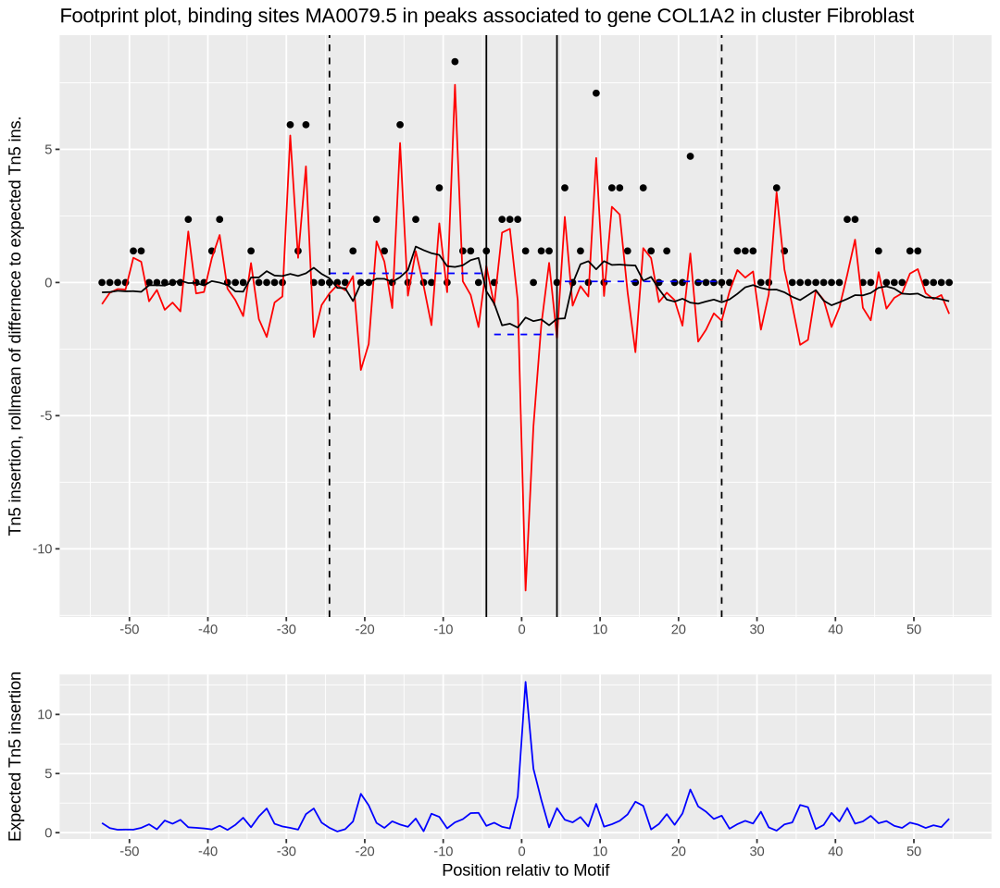

In [82]:
options(repr.plot.width=9, repr.plot.height=8)
footprint_plots_by_TF(object=object_w_net, gene='COL1A2', cluster="Fibroblast", TF="SP1", path=NULL)

TF provided, plotting all motifs for TF



[1] "2026-04-30 08:43:21 CEST"
GRanges object with 3 ranges and 1 metadata column:
      seqnames            ranges strand |     score
         <Rle>         <IRanges>  <Rle> | <numeric>
  [1]    chr17 50201548-50201556      + |   15.9318
  [2]    chr17 50209686-50209694      + |   14.2826
  [3]    chr17 50221703-50221711      - |   15.9318
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-30 08:43:21 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


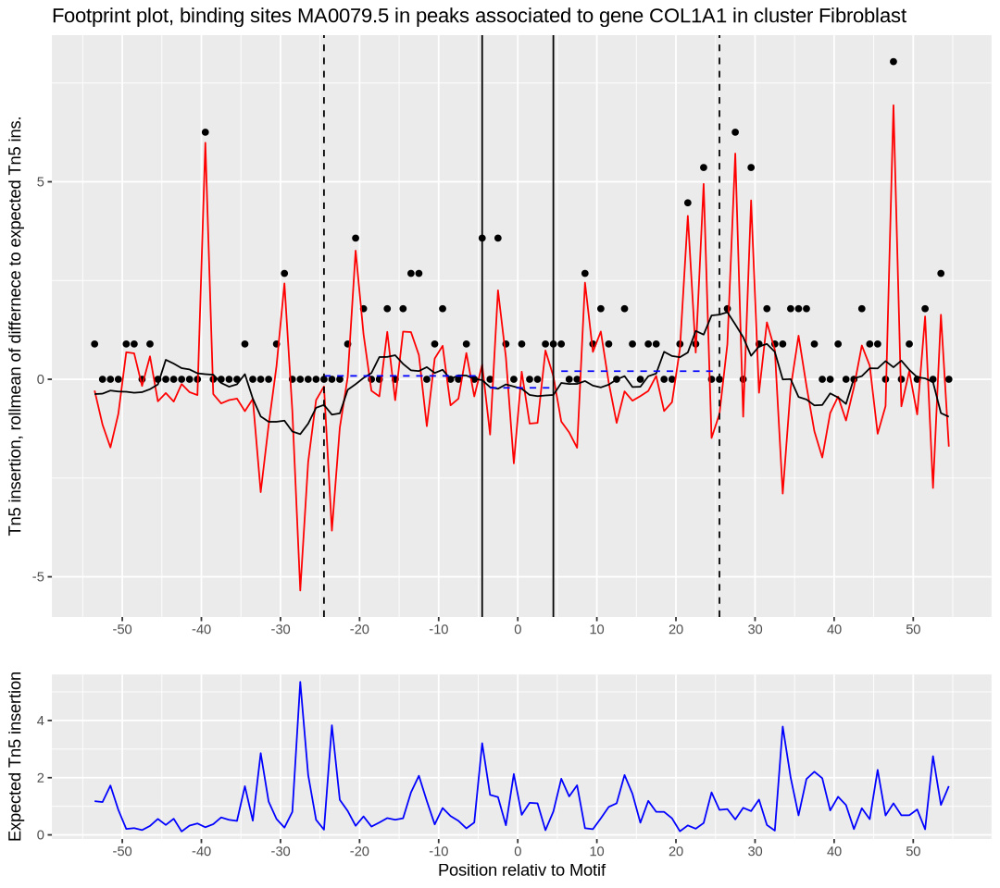

In [81]:
options(repr.plot.width=9, repr.plot.height=8)
footprint_plots_by_TF(object=object_w_net, gene='COL1A1', cluster="Fibroblast", TF="SP1", path=NULL)

In [3]:
object_w_net@misc$motif2TF[["MA0137.4"]]

[1] "STAT1"

In [4]:
object_w_net@misc$motif2TF[["MA0517.2"]]

[1] "STAT1" "STAT2"

TF provided, plotting all motifs for TF



[1] "2026-04-30 09:16:39 CEST"
GRanges object with 3 ranges and 1 metadata column:
      seqnames            ranges strand |     score
         <Rle>         <IRanges>  <Rle> | <numeric>
  [1]    chr17 50201548-50201556      + |   15.9318
  [2]    chr17 50209686-50209694      + |   14.2826
  [3]    chr17 50221703-50221711      - |   15.9318
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Warning message:
"The `slot` argument of `GetAssayData()` is deprecated as of SeuratObject 5.0.0.
ℹ Please use the `layer` argument instead."
Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-30 09:16:39 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


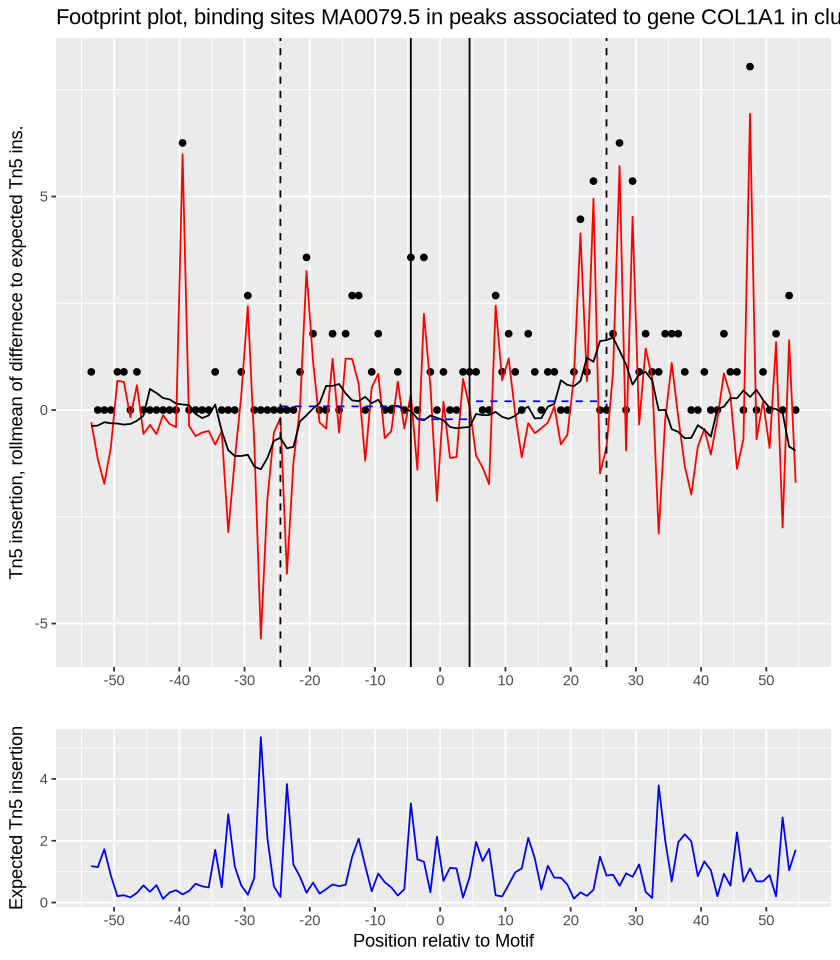

In [5]:
options(repr.plot.width=7, repr.plot.height=8)
footprint_plots_by_TF(object=object_w_net, gene='COL1A1', cluster="Fibroblast", TF="SP1", path=NULL)

In [70]:
object_w_net@misc$motif2TF[["MA1130.2"]]

[1] "FOSL2" "JUN"

In [69]:
object_w_net@misc$motif2TF[["MA0478.2"]]

[1] "FOSL2"

In [18]:
object_w_net@misc$context_subNetwork$colagen_fibral_orga_complete %>%
    filter(priorTF==FALSE) %>%
    filter(to=="ANXA2")

,from,to,color,priorTF,reg_type,in.prom
,<chr>,<chr>,<chr>,<lgl>,<int>,<int>
ANXA2.3,SREBF2,ANXA2,red,FALSE,2,1
ANXA2.4,FOXB1,ANXA2,red,FALSE,2,1
ANXA2.5,FOXC1,ANXA2,green,FALSE,2,3
ANXA2.6,TP53,ANXA2,red,FALSE,2,1
ANXA2.7,FOSB,ANXA2,red,FALSE,2,1
ANXA2.8,JUN,ANXA2,red,FALSE,2,1
ANXA2.9,CUX1,ANXA2,red,FALSE,2,3
ANXA2.10,JUNB,ANXA2,red,FALSE,2,1
ANXA2.11,NFIC,ANXA2,red,FALSE,2,3


In [16]:
df <- object_w_net@misc$context_subNetwork$colagen_fibral_orga_complete
motifs_per_gene <- df %>%
  filter(color %in% c("green", "yellow", "red")) %>%
  group_by(to) %>%
  summarise(
    n_motifs_enriched = n_distinct(from),
    .groups = "drop"
  )
motifs_per_gene

to,n_motifs_enriched
<chr>,<int>
AEBP1,69
ANXA2,13
COL12A1,41
COL14A1,84
COL1A1,82
COL1A2,125
COL3A1,86
COL5A1,119
COL5A2,108


In [20]:
df <- object_w_net@misc$filtered.motif_enrichment 
tmp <- df %>%
    filter(gene == "ANXA2")

unique_motifs <- unique(tmp$motif)

In [21]:
length(unique_motifs)

[1] 43

In [22]:
unique_motifs <- unlist(unique_motifs)

tfs <- object_w_net@misc$motif2TF[unique_motifs] %>%
  unlist(use.names = FALSE) %>%
  unique()

In [23]:
length(unique(tfs))

[1] 43

In [101]:
motif_summary_joined

gene,n_motifs_only_distal,n_motifs_only_distal_enriched,n_motifs_proximal
<chr>,<int>,<int>,<int>
ADAMTS2,217,198,0
AEBP1,71,70,54
ANXA2,47,43,0
COL12A1,7,7,66
COL14A1,192,164,0
COL1A1,230,156,21
COL1A2,258,113,132
COL3A1,282,138,0
COL5A1,516,226,0


In [6]:
object_w_net@misc$context_subNetwork$colagen_fibral_orga_complete

,from,to,color,priorTF,reg_type,in.prom
,<chr>,<chr>,<chr>,<lgl>,<int>,<int>
ADAMTS7.1,HR,ADAMTS7,black,TRUE,2,1
ADAMTS7.2,HTATIP2,ADAMTS7,black,TRUE,2,1
ADAMTS7.3,SSRP1,ADAMTS7,black,TRUE,2,1
ADAMTS7.4,TFAP2A,ADAMTS7,black,TRUE,2,1
ADAMTS7.5,ZBTB16,ADAMTS7,black,TRUE,2,1
AEBP1.1,SP1,AEBP1,red,TRUE,1,3
AEBP1.2,SP3,AEBP1,green,TRUE,1,3
AEBP1.3,INSM1,AEBP1,red,FALSE,1,3
AEBP1.4,ZIC1,AEBP1,red,FALSE,1,1
